SetUp

In [1]:
# pip install opencv-python matplotlib numpy pandas

In [2]:
import pickle
import time
from pathlib import Path

import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%config InlineBackend.figure_formats = ['jpeg']

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
SEG_PKL = ROOT / 'data' / 'processed' / 'dataset_seg.pkl'
PCD_PKL = ROOT / 'data' / 'processed' / 'dataset_pcd.pkl'

FLOOR, MOTOR, IGNORE = 0, 1, 255
CLASS_COLORS = {FLOOR: (0, 200, 0), MOTOR: (0, 0, 230), IGNORE: (150, 150, 150)}
rng = np.random.default_rng(0)

Step 1: Load Dataset

In [3]:
with open(SEG_PKL, 'rb') as f:
    data = pickle.load(f)

X, Y, meta, geo = data['X'], data['Y'], data['meta'], data['geo']

print('X:', X.shape, X.dtype)
print('Y:', Y.shape, Y.dtype)
print('pixels  floor:', int(np.sum(Y == FLOOR)), '| motorcycle:', int(np.sum(Y == MOTOR)), '| ignore:', int(np.sum(Y == IGNORE)))
pd.crosstab(meta['weather'], meta['split'], margins=True)

X: (92, 540, 960, 3) uint8
Y: (92, 540, 960) uint8


pixels  floor: 5136886 | motorcycle: 12999420 | ignore: 29556494


split,test,train,val,All
weather,,,,
cloudy,0,9,0,9
dusk,9,0,0,9
rain,0,18,9,27
sunny,17,26,4,47
All,26,53,13,92


dataset berisi frame 960 × 540 (`X`), mask nya (`Y`) dan meta per frame. pembagian train / val / test sudah dibuat per hari di notebook sebelumnya. di notebook ini statistik warna hanya diambil dari **train**, threshold dipilih di **val**, dan angka akhir dilaporkan di **test**, supaya hasil nya tidak bocor.

Step 2: Color Spaces

In [4]:
def to_spaces(img):
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)       # H 0-179, S 0-255, V 0-255
    lab = cv.cvtColor(img, cv.COLOR_BGR2LAB)       # L, a (green-red), b (blue-yellow), all 0-255
    return {'gray': gray, 'H': hsv[:, :, 0], 'S': hsv[:, :, 1], 'V': hsv[:, :, 2],
            'L': lab[:, :, 0], 'a': lab[:, :, 1], 'b': lab[:, :, 2]}

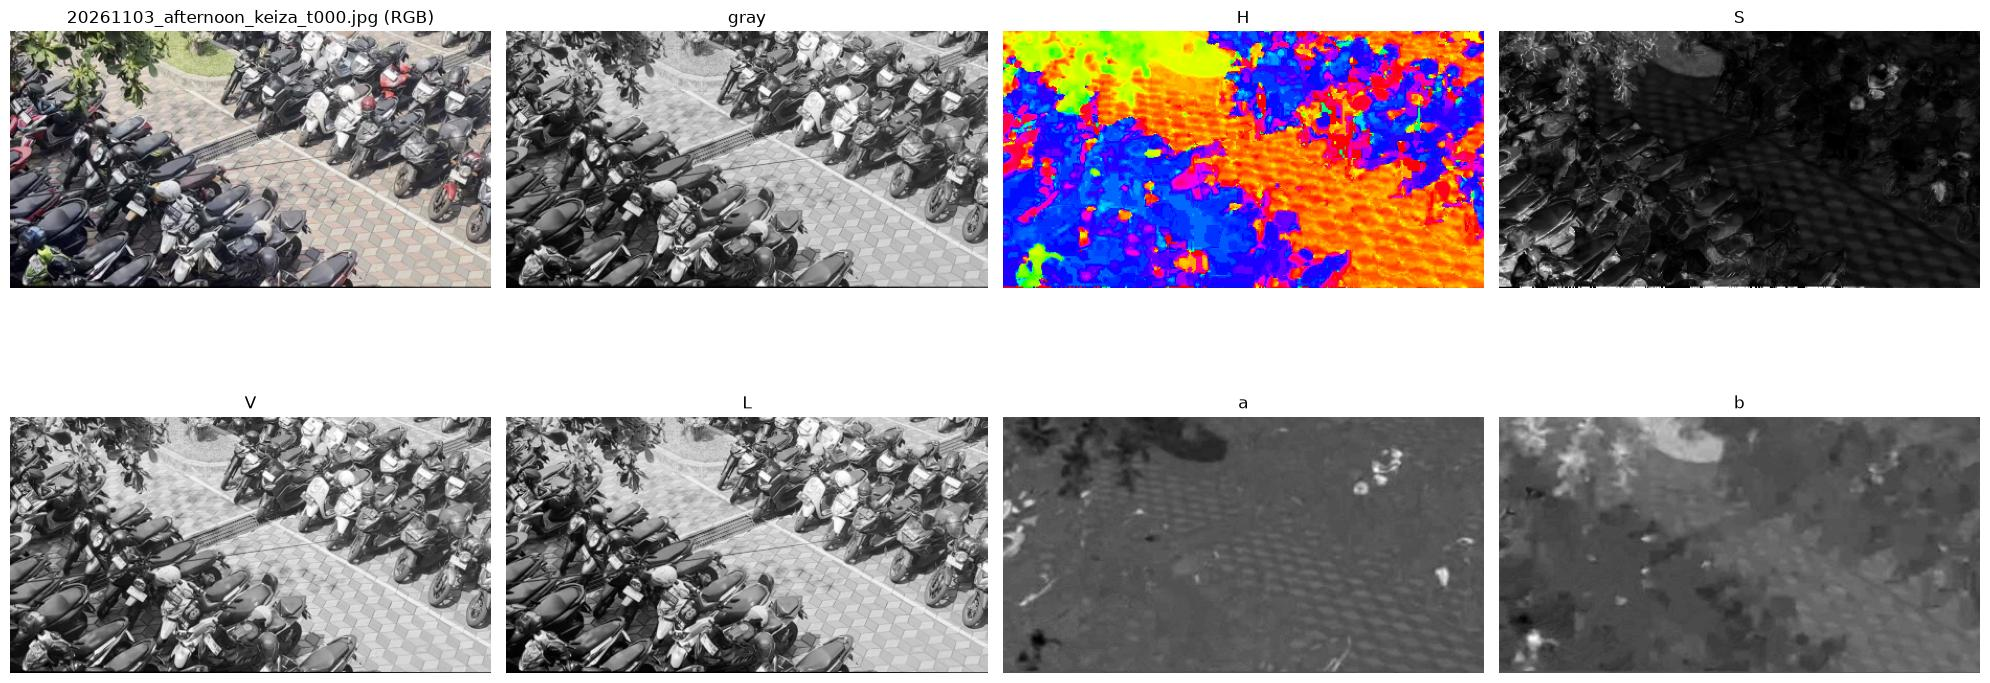

In [5]:
DEMO = int(np.argmax(meta['weather'] == 'sunny'))
img = X[DEMO]
spaces = to_spaces(img)

ys, xs = np.where(Y[DEMO] != IGNORE)
y0, x0 = max(0, int(ys.mean()) - 130), max(0, int(xs.mean()) - 230)   # zoom on the ROI

plt.figure(figsize=(20, 9))
plt.subplot(2, 4, 1)
plt.imshow(img[y0:y0 + 260, x0:x0 + 460, ::-1])
plt.title(f"{meta['frame'][DEMO]} (RGB)")
plt.axis('off')
for k, name in enumerate(['gray', 'H', 'S', 'V', 'L', 'a', 'b']):
    plt.subplot(2, 4, k + 2)
    plt.imshow(spaces[name][y0:y0 + 260, x0:x0 + 460], cmap='hsv' if name == 'H' else 'gray')
    plt.title(name)
    plt.axis('off')
plt.tight_layout()
plt.show()

- **gray** hanya menyimpan kecerahan, jadi motor hitam dan ubin abu-abu gelap bisa terlihat sama.
- **hsv** memisahkan warna (**H**ue, 0–179 di opencv), kemurnian warna (**S**aturation) dan kecerahan (**V**alue). ide nya: bayangan dan sore hari terutama mengubah v, sedangkan h relatif tetap.
- **lab** memisahkan kecerahan (**L**) dari dua sumbu warna: **a** (hijau ↔ merah) dan **b** (biru ↔ kuning). paving merah bata punya nilai a yang tinggi.

Step 3: Hue Wrap-Around

In [6]:
def sample_pixels(split, per_frame=20000):
    # random labeled pixels of every frame in one split -> one table, one row per pixel
    rows = []
    for i in np.where(meta['split'] == split)[0]:
        valid = np.flatnonzero(Y[i] != IGNORE)
        pick = rng.choice(valid, min(per_frame, len(valid)), replace=False)
        sp = to_spaces(X[i])
        part = {name: sp[name].ravel()[pick] for name in sp}
        part['label'] = Y[i].ravel()[pick]
        part['weather'] = meta['weather'][i]
        rows.append(pd.DataFrame(part))
    return pd.concat(rows, ignore_index=True)


train_px = sample_pixels('train')
print('sampled train pixels:', len(train_px), '| floor:', int(np.sum(train_px['label'] == FLOOR)),
      '| motorcycle:', int(np.sum(train_px['label'] == MOTOR)))

sampled train pixels: 1060000 | floor: 278499 | motorcycle: 781501


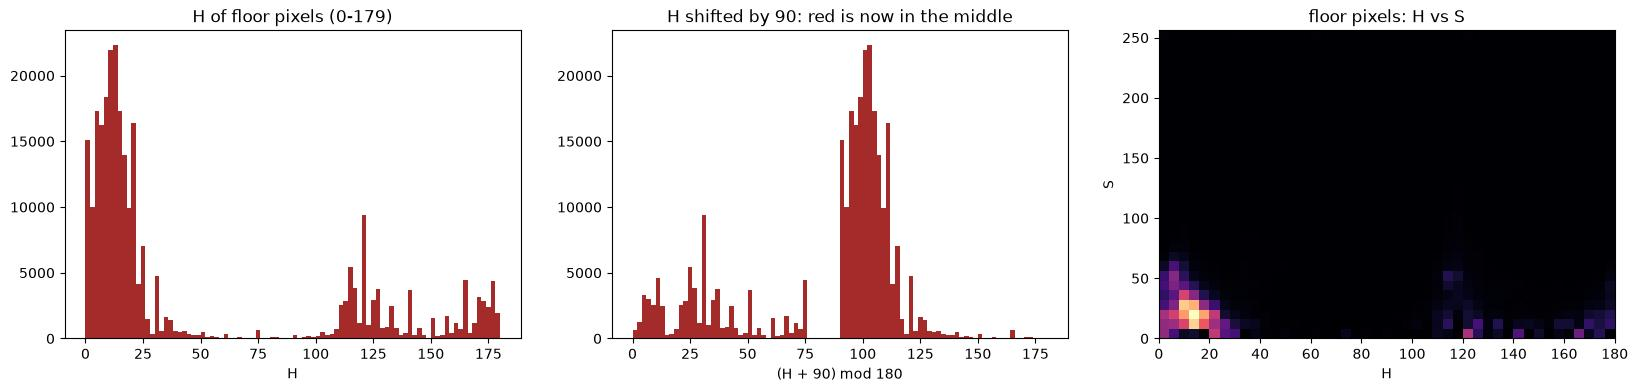

floor pixels with H < 15 or H > 165 (red)  : 52.4%
floor pixels with S < 40 (hue is unreliable): 82.8%


In [7]:
floor_h = train_px.loc[train_px['label'] == FLOOR, 'H']
floor_s = train_px.loc[train_px['label'] == FLOOR, 'S']

plt.figure(figsize=(20, 4))
plt.subplot(1, 3, 1)
plt.hist(floor_h, bins=90, range=(0, 180), color='brown')
plt.title('H of floor pixels (0-179)')
plt.xlabel('H')
plt.subplot(1, 3, 2)
plt.hist((floor_h + 90) % 180, bins=90, range=(0, 180), color='brown')
plt.title('H shifted by 90: red is now in the middle')
plt.xlabel('(H + 90) mod 180')
plt.subplot(1, 3, 3)
plt.hist2d(floor_h, floor_s, bins=[45, 32], range=[[0, 180], [0, 256]], cmap='magma')
plt.title('floor pixels: H vs S')
plt.xlabel('H')
plt.ylabel('S')
plt.show()

print('floor pixels with H < 15 or H > 165 (red)  :', f"{100 * np.mean((floor_h < 15) | (floor_h > 165)):.1f}%")
print('floor pixels with S < 40 (hue is unreliable):', f"{100 * np.mean(floor_s < 40):.1f}%")

hue berbentuk **lingkaran**: merah ada di dua ujung (h ≈ 0 dan h ≈ 179), jadi ubin merah yang sama bisa terbaca h = 2 atau h = 177. kalau h dipakai langsung sebagai angka, kedua nilai ini terlihat sangat jauh padahal warna nya sama. setelah digeser 90, merah pindah ke tengah dan histogram nya menjadi satu puncak. cara lain adalah memakai cos(h) dan sin(h).

masalah kedua: **hue tidak berarti kalau saturasi nya rendah**. ubin abu-abu, motor hitam, putih dan silver hampir tidak punya warna, jadi h nya acak (terlihat sebagai garis horizontal di bagian bawah histogram h vs s). karena itu h harus selalu dipakai bersama s.

Step 4: Channel Histograms per Class

In [8]:
def overlap(a, b, bins=64, value_range=(0, 256)):
    # overlap of the two normalised histograms: 0 = fully separated, 1 = identical
    ha, _ = np.histogram(a, bins=bins, range=value_range)
    hb, _ = np.histogram(b, bins=bins, range=value_range)
    return np.sum(np.minimum(ha / ha.sum(), hb / hb.sum()))


train_px['H shifted'] = (train_px['H'].astype(int) + 90) % 180
channels = ['gray', 'H shifted', 'S', 'V', 'L', 'a', 'b']

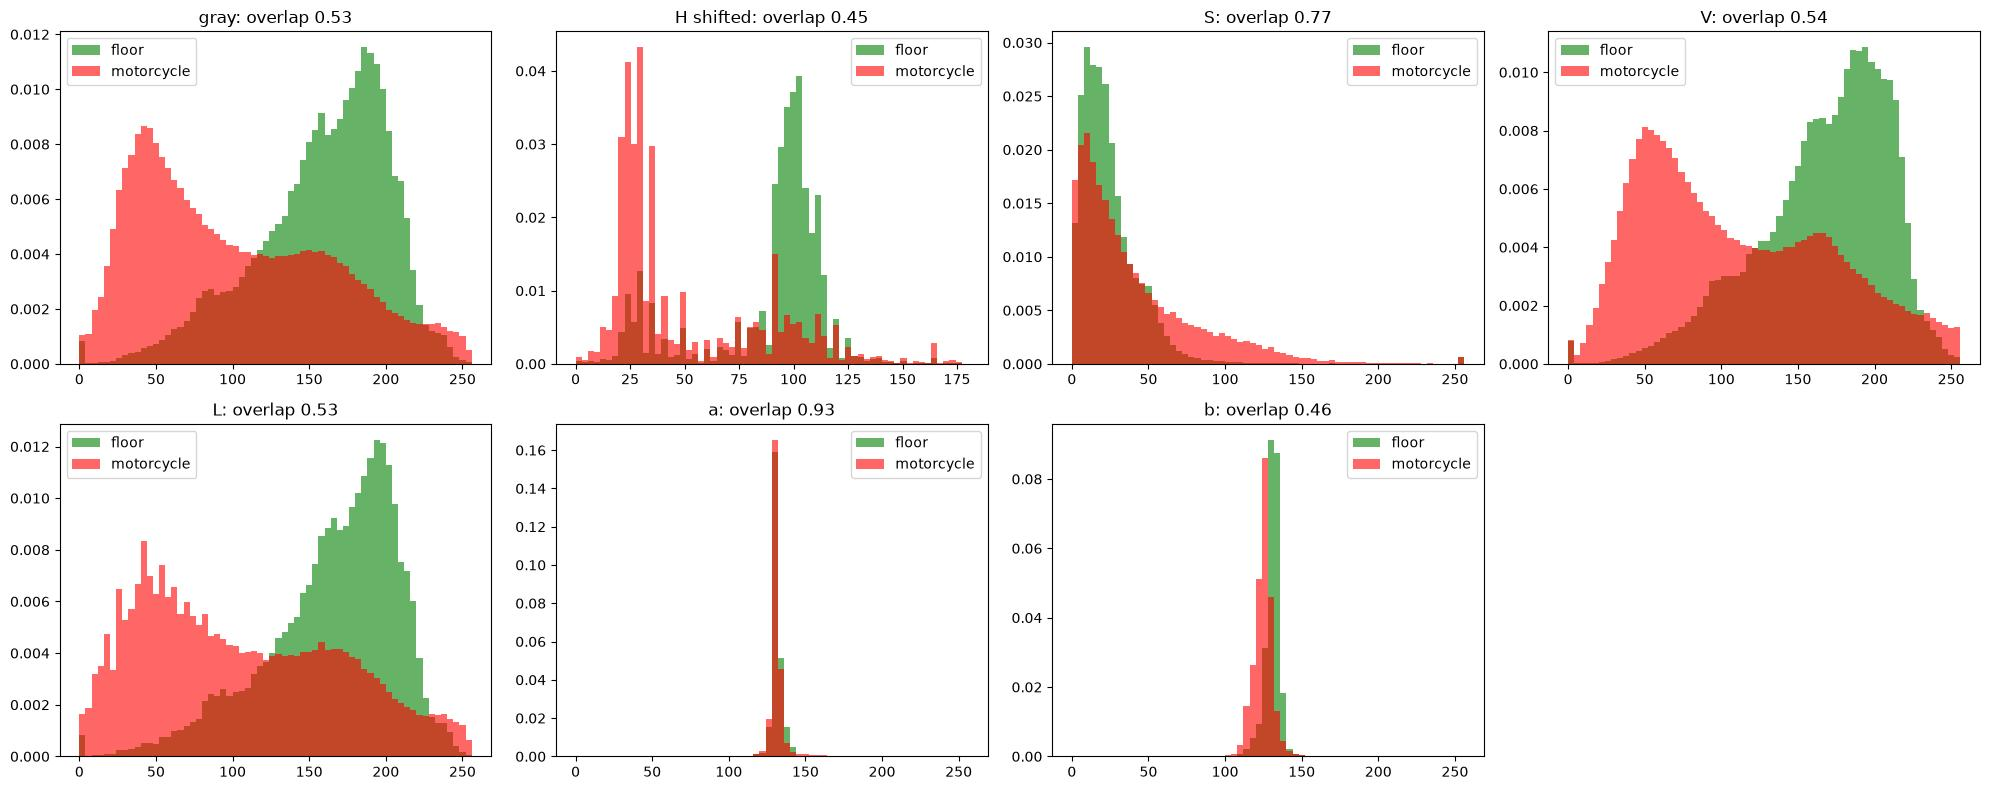

,channel,overlap
0,H shifted,0.449
1,b,0.462
2,gray,0.532
3,L,0.533
4,V,0.542
5,S,0.774
6,a,0.934


In [9]:
floor_px = train_px[train_px['label'] == FLOOR]
motor_px = train_px[train_px['label'] == MOTOR]

plt.figure(figsize=(20, 8))
scores = []
for k, name in enumerate(channels):
    value_range = (0, 180) if name == 'H shifted' else (0, 256)
    ov = overlap(floor_px[name], motor_px[name], value_range=value_range)
    scores.append([name, round(ov, 3)])

    plt.subplot(2, 4, k + 1)
    plt.hist(floor_px[name], bins=64, range=value_range, density=True, alpha=0.6, color='green', label='floor')
    plt.hist(motor_px[name], bins=64, range=value_range, density=True, alpha=0.6, color='red', label='motorcycle')
    plt.title(f'{name}: overlap {ov:.2f}')
    plt.legend()
plt.tight_layout()
plt.show()

scores = pd.DataFrame(scores, columns=['channel', 'overlap']).sort_values('overlap').reset_index(drop=True)
scores

setiap histogram menunjukkan sebaran nilai satu kanal untuk piksel lantai (hijau) dan motor (merah). semakin kecil **overlap** (luas bagian yang tumpang tindih dari dua histogram yang sudah dinormalisasi), semakin mudah kanal itu memisahkan lantai dari motor. overlap 0 artinya terpisah sempurna, overlap 1 artinya sebaran nya sama persis.

Step 5: Lighting Conditions

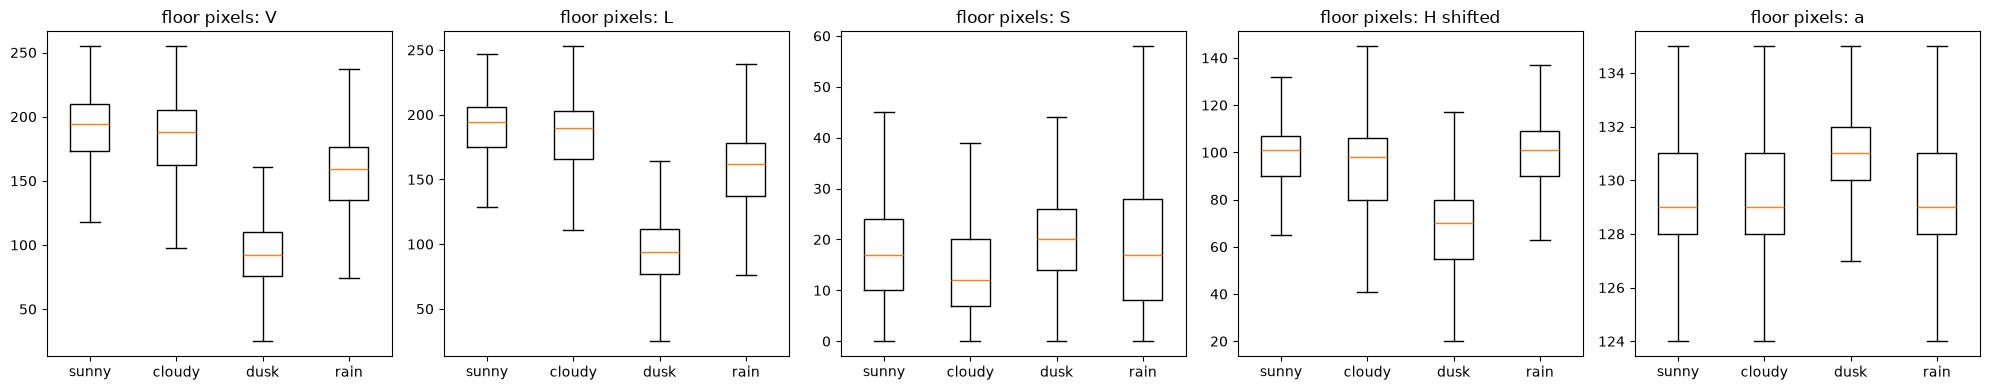

,V,L,S,H shifted,a
weather,,,,,
sunny,194.0,194.0,17.0,101.0,129.0
cloudy,188.0,190.0,12.0,98.0,129.0
dusk,92.0,94.0,20.0,70.0,131.0
rain,159.0,162.0,17.0,101.0,129.0
spread (max - min),102.0,100.0,8.0,31.0,2.0


In [10]:
conditions = [w for w in ['sunny', 'cloudy', 'dusk', 'rain'] if w in set(meta['weather'])]

cond_px = []
for w in conditions:
    for i in np.where(meta['weather'] == w)[0][:6]:          # up to 6 frames per condition, any split
        valid = np.flatnonzero(Y[i] == FLOOR)
        pick = rng.choice(valid, min(10000, len(valid)), replace=False)
        sp = to_spaces(X[i])
        cond_px.append(pd.DataFrame({'weather': w, 'V': sp['V'].ravel()[pick], 'S': sp['S'].ravel()[pick],
                                     'H shifted': (sp['H'].ravel()[pick].astype(int) + 90) % 180,
                                     'L': sp['L'].ravel()[pick], 'a': sp['a'].ravel()[pick]}))
cond_px = pd.concat(cond_px, ignore_index=True)

plt.figure(figsize=(20, 4))
for k, name in enumerate(['V', 'L', 'S', 'H shifted', 'a']):
    plt.subplot(1, 5, k + 1)
    plt.boxplot([cond_px.loc[cond_px['weather'] == w, name] for w in conditions], showfliers=False)
    plt.xticks(range(1, len(conditions) + 1), conditions)
    plt.title(f'floor pixels: {name}')
plt.tight_layout()
plt.show()

medians = cond_px.groupby('weather')[['V', 'L', 'S', 'H shifted', 'a']].median().loc[conditions]
medians.loc['spread (max - min)'] = medians.max() - medians.min()
medians

lantai yang sama terlihat berbeda di setiap kondisi. baris **spread** menunjukkan seberapa jauh median piksel lantai bergeser antar kondisi: kanal dengan spread kecil lebih **tahan terhadap perubahan cahaya**, jadi model yang belajar di hari cerah lebih mungkin tetap benar saat sore atau hujan.

Step 6: CLAHE on V

In [11]:
clahe = cv.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))


def clahe_gray(img):
    return clahe.apply(cv.cvtColor(img, cv.COLOR_BGR2GRAY))


def clahe_v(img):
    hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)
    hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])   # only V changes, H and S (the colour) stay the same
    return hsv

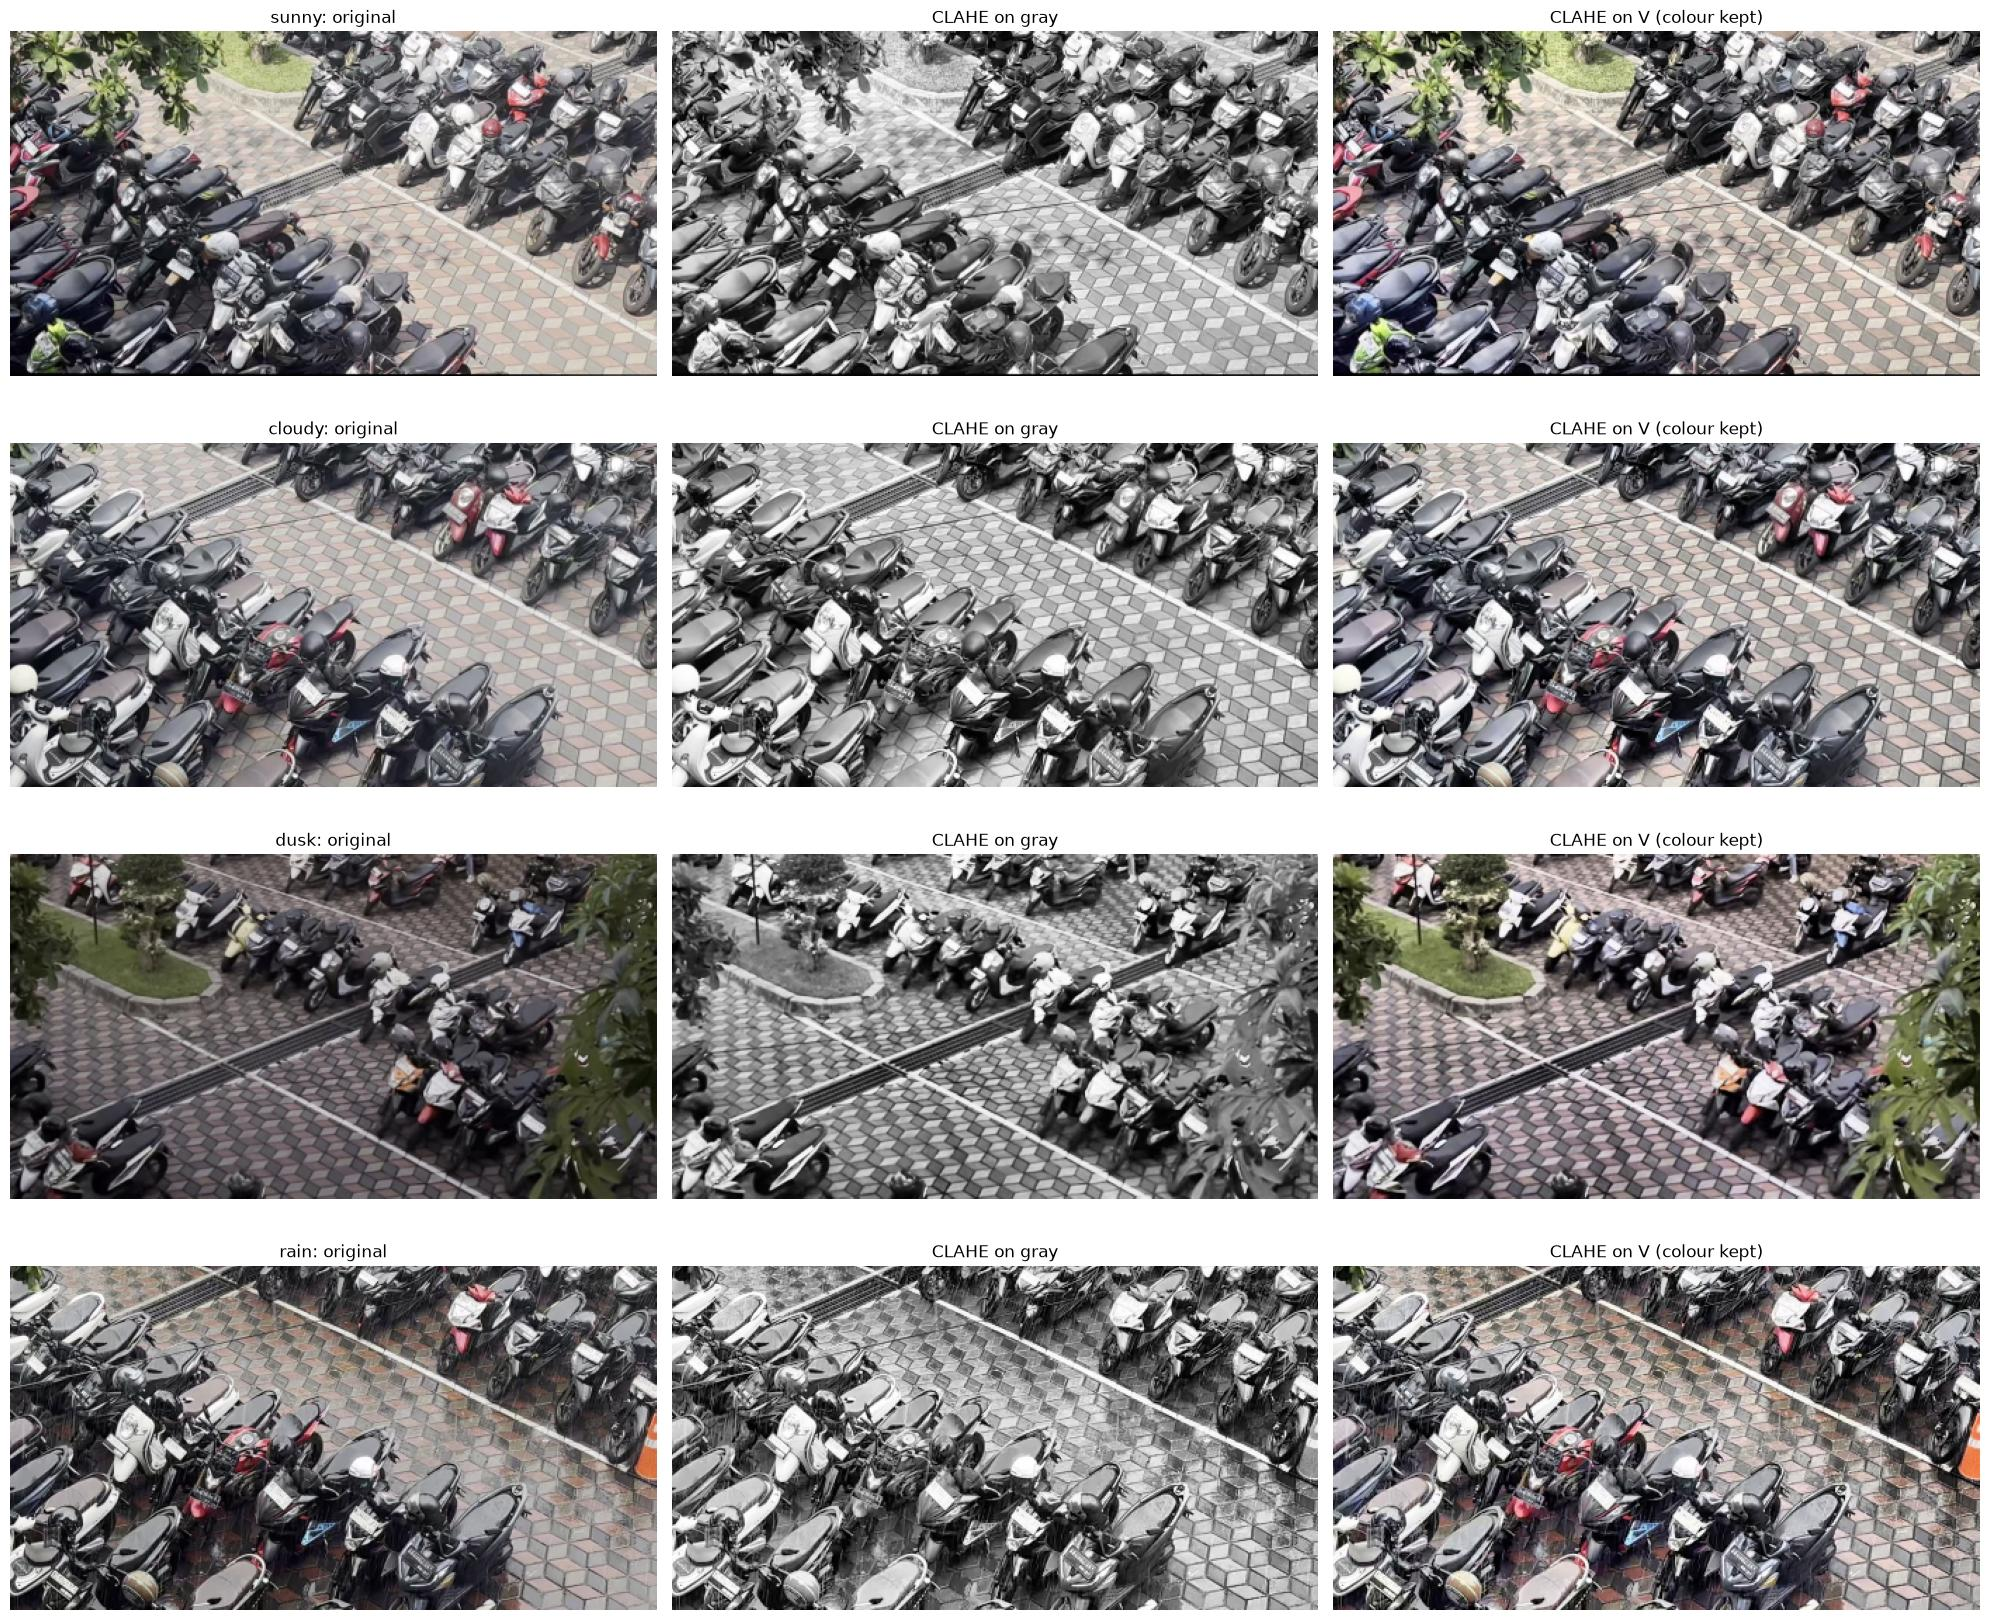

In [12]:
show = [int(np.argmax(meta['weather'] == w)) for w in conditions]

plt.figure(figsize=(20, 4.2 * len(show)))
for r in range(len(show)):
    i = show[r]
    crop = (slice(y0, y0 + 260), slice(x0, x0 + 460))
    plt.subplot(len(show), 3, 3 * r + 1)
    plt.imshow(X[i][crop][:, :, ::-1])
    plt.title(f"{meta['weather'][i]}: original")
    plt.axis('off')
    plt.subplot(len(show), 3, 3 * r + 2)
    plt.imshow(clahe_gray(X[i])[crop], cmap='gray')
    plt.title('CLAHE on gray')
    plt.axis('off')
    plt.subplot(len(show), 3, 3 * r + 3)
    plt.imshow(cv.cvtColor(clahe_v(X[i]), cv.COLOR_HSV2BGR)[crop][:, :, ::-1])
    plt.title('CLAHE on V (colour kept)')
    plt.axis('off')
plt.tight_layout()
plt.show()

In [13]:
v_before, v_after = [], []
for w in conditions:
    for i in np.where(meta['weather'] == w)[0][:6]:
        floor = Y[i] == FLOOR
        v_before.append([w, np.median(cv.cvtColor(X[i], cv.COLOR_BGR2HSV)[:, :, 2][floor])])
        v_after.append([w, np.median(clahe_v(X[i])[:, :, 2][floor])])
v_before = pd.DataFrame(v_before, columns=['weather', 'V']).groupby('weather')['V'].median().loc[conditions]
v_after = pd.DataFrame(v_after, columns=['weather', 'V']).groupby('weather')['V'].median().loc[conditions]

ov_before = overlap(floor_px['V'], motor_px['V'])
clahe_px = []
for i in np.where(meta['split'] == 'train')[0]:
    v = clahe_v(X[i])[:, :, 2]
    clahe_px.append([v[Y[i] == FLOOR][::50], v[Y[i] == MOTOR][::50]])
ov_after = overlap(np.concatenate([c[0] for c in clahe_px]), np.concatenate([c[1] for c in clahe_px]))

print('median V of the floor per condition')
print('  before CLAHE:', v_before.round(0).to_dict(), '-> spread', int(v_before.max() - v_before.min()))
print('  after CLAHE :', v_after.round(0).to_dict(), '-> spread', int(v_after.max() - v_after.min()))
print(f'overlap floor vs motorcycle in V: before {ov_before:.3f}, after CLAHE {ov_after:.3f}')

median V of the floor per condition
  before CLAHE: {'sunny': 194.0, 'cloudy': 188.0, 'dusk': 92.0, 'rain': 160.0} -> spread 102
  after CLAHE : {'sunny': 192.0, 'cloudy': 183.0, 'dusk': 135.0, 'rain': 164.0} -> spread 56
overlap floor vs motorcycle in V: before 0.542, after CLAHE 0.646


**clahe** (contrast limited adaptive histogram equalization) meratakan histogram per tile 8 × 8, dengan batas (clip limit 2.0) supaya noise tidak ikut diperkuat. kalau clahe diterapkan pada grayscale, informasi warna hilang. karena itu clahe diterapkan **hanya pada kanal v**, lalu h dan s dibiarkan, sehingga kontras di bagian gelap (bayangan gedung, sore, hujan) naik tanpa mengubah warna paving dan motor. angka di atas menunjukkan apakah clahe membuat kecerahan lantai di berbagai kondisi menjadi lebih mirip (spread lebih kecil), dan apakah v tetap bisa membedakan lantai dari motor.

Step 7: Noise and Texture

In [14]:
def local_std(channel, size=9):
    # texture: standard deviation of the pixels around each pixel
    c = channel.astype(np.float32)
    mean = cv.blur(c, (size, size))
    mean_sq = cv.blur(c * c, (size, size))
    return np.sqrt(np.maximum(mean_sq - mean * mean, 0))


def edge_density(channel, size=9):
    edges = cv.Canny(channel, 50, 150)
    return cv.blur((edges > 0).astype(np.float32), (size, size))

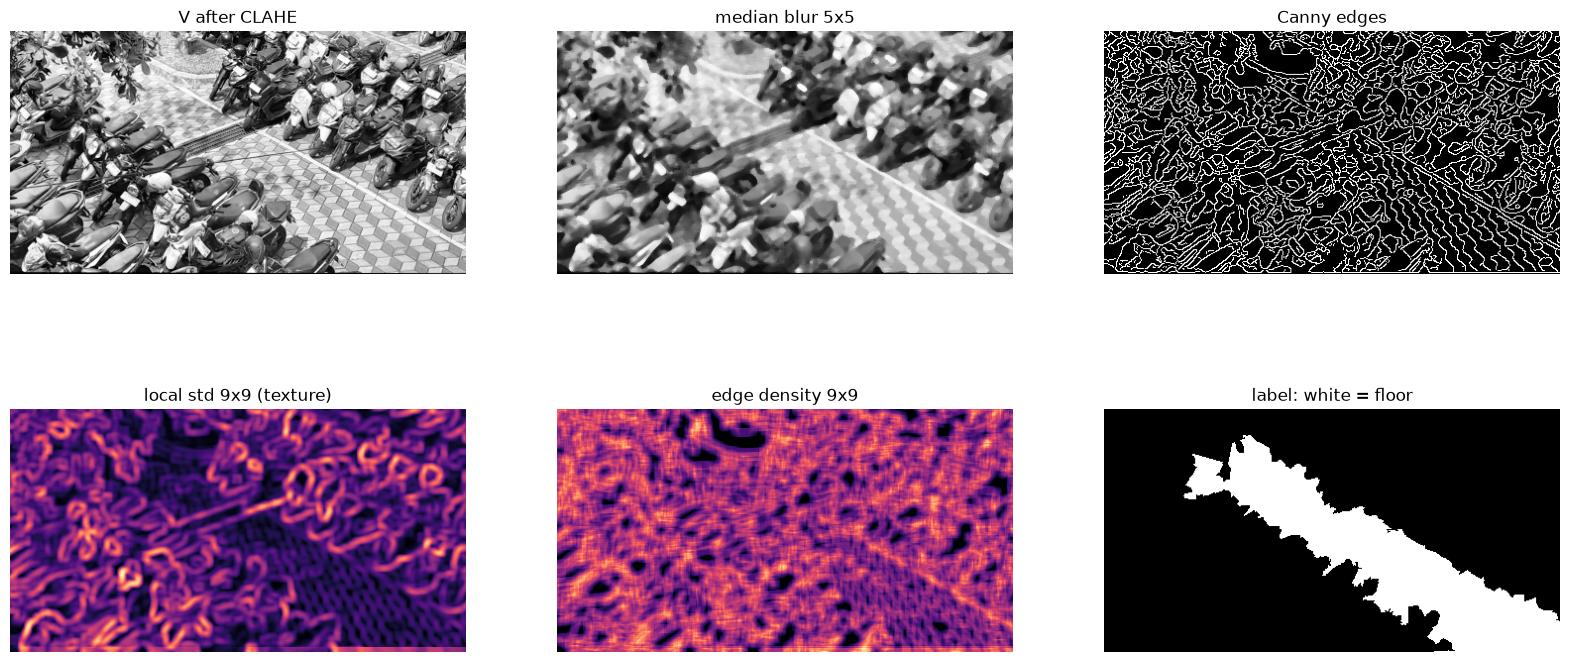

In [15]:
i = DEMO
v = clahe_v(X[i])[:, :, 2]
v_blur = cv.medianBlur(v, 5)
crop = (slice(y0, y0 + 260), slice(x0, x0 + 460))

plt.figure(figsize=(20, 9))
plt.subplot(2, 3, 1)
plt.imshow(v[crop], cmap='gray')
plt.title('V after CLAHE')
plt.axis('off')
plt.subplot(2, 3, 2)
plt.imshow(v_blur[crop], cmap='gray')
plt.title('median blur 5x5')
plt.axis('off')
plt.subplot(2, 3, 3)
plt.imshow(cv.Canny(v_blur, 50, 150)[crop], cmap='gray')
plt.title('Canny edges')
plt.axis('off')
plt.subplot(2, 3, 4)
plt.imshow(local_std(v_blur)[crop], cmap='magma')
plt.title('local std 9x9 (texture)')
plt.axis('off')
plt.subplot(2, 3, 5)
plt.imshow(edge_density(v_blur)[crop], cmap='magma')
plt.title('edge density 9x9')
plt.axis('off')
plt.subplot(2, 3, 6)
plt.imshow(cv.cvtColor(np.uint8(Y[i] == FLOOR) * 255, cv.COLOR_GRAY2RGB)[crop])
plt.title('label: white = floor')
plt.axis('off')
plt.show()

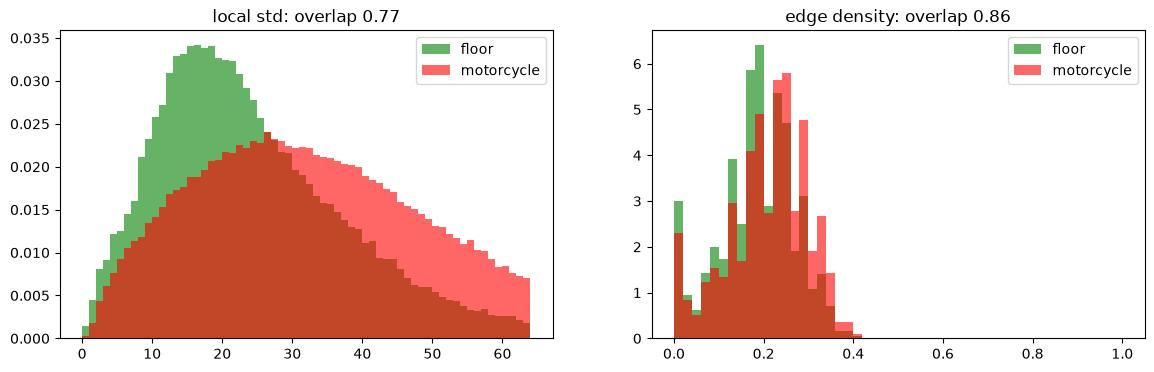

In [16]:
tex_floor, tex_motor, ed_floor, ed_motor = [], [], [], []
for i in np.where(meta['split'] == 'train')[0]:
    v_blur = cv.medianBlur(clahe_v(X[i])[:, :, 2], 5)
    t, e = local_std(v_blur), edge_density(v_blur)
    tex_floor.append(t[Y[i] == FLOOR][::50])
    tex_motor.append(t[Y[i] == MOTOR][::50])
    ed_floor.append(e[Y[i] == FLOOR][::50])
    ed_motor.append(e[Y[i] == MOTOR][::50])
tex_floor, tex_motor = np.concatenate(tex_floor), np.concatenate(tex_motor)
ed_floor, ed_motor = np.concatenate(ed_floor), np.concatenate(ed_motor)

plt.figure(figsize=(14, 4))
plt.subplot(1, 2, 1)
plt.hist(tex_floor, bins=64, range=(0, 64), density=True, alpha=0.6, color='green', label='floor')
plt.hist(tex_motor, bins=64, range=(0, 64), density=True, alpha=0.6, color='red', label='motorcycle')
plt.title(f'local std: overlap {overlap(tex_floor, tex_motor, value_range=(0, 64)):.2f}')
plt.legend()
plt.subplot(1, 2, 2)
plt.hist(ed_floor, bins=50, range=(0, 1), density=True, alpha=0.6, color='green', label='floor')
plt.hist(ed_motor, bins=50, range=(0, 1), density=True, alpha=0.6, color='red', label='motorcycle')
plt.title(f'edge density: overlap {overlap(ed_floor, ed_motor, bins=50, value_range=(0, 1)):.2f}')
plt.legend()
plt.show()

**median blur** 5 × 5 menghapus noise kecil (bintik terang, pantulan) tapi tetap menjaga tepi, karena setiap piksel diganti dengan median tetangga nya, bukan rata-rata. lalu dihitung dua fitur tekstur:

- **local std**: simpangan baku kecerahan di jendela 9 × 9. lantai paving punya pola hexagon yang teratur dan kontras nya sedang, sedangkan motor punya pantulan terang dan bagian hitam yang bersebelahan, jadi local std nya tinggi.
- **edge density**: persentase piksel tepi canny di jendela 9 × 9.

fitur ini melengkapi warna. ubin abu-abu dan motor silver bisa punya h, s dan v yang mirip, tapi tekstur nya berbeda.

Step 8: Baseline Segmentation (Naive Bayes on HSV + Texture)

In [17]:
H_BINS, S_BINS, T_BINS = 30, 32, 32


def pcd_features(img):
    hsv = clahe_v(img)
    hsv[:, :, 2] = cv.medianBlur(hsv[:, :, 2], 5)
    h_bin = np.minimum(hsv[:, :, 0].astype(int) * H_BINS // 180, H_BINS - 1)
    s_bin = np.minimum(hsv[:, :, 1].astype(int) * S_BINS // 256, S_BINS - 1)
    t_bin = np.minimum(local_std(hsv[:, :, 2]).astype(int) * T_BINS // 64, T_BINS - 1)
    return h_bin, s_bin, t_bin


def fit_histograms(split):
    # count how often every (H, S) bin and every texture bin appears in floor and in motorcycle pixels
    hs = np.ones((2, H_BINS, S_BINS))   # start at 1 so no bin has probability 0
    tex = np.ones((2, T_BINS))
    for i in np.where(meta['split'] == split)[0]:
        h_bin, s_bin, t_bin = pcd_features(X[i])
        for cls in [FLOOR, MOTOR]:
            m = Y[i] == cls
            np.add.at(hs[cls], (h_bin[m], s_bin[m]), 1)
            np.add.at(tex[cls], t_bin[m], 1)
    prior = np.array([hs[FLOOR].sum(), hs[MOTOR].sum()])
    return hs / hs.sum(axis=(1, 2), keepdims=True), tex / tex.sum(axis=1, keepdims=True), prior / prior.sum()


def log_ratio(img, model, use_texture):
    # log P(floor | pixel) - log P(motorcycle | pixel), assuming colour and texture are independent
    p_hs, p_tex, prior = model
    h_bin, s_bin, t_bin = pcd_features(img)
    score = np.log(p_hs[FLOOR][h_bin, s_bin]) - np.log(p_hs[MOTOR][h_bin, s_bin]) + np.log(prior[FLOOR] / prior[MOTOR])
    if use_texture:
        score += np.log(p_tex[FLOOR][t_bin]) - np.log(p_tex[MOTOR][t_bin])
    return score

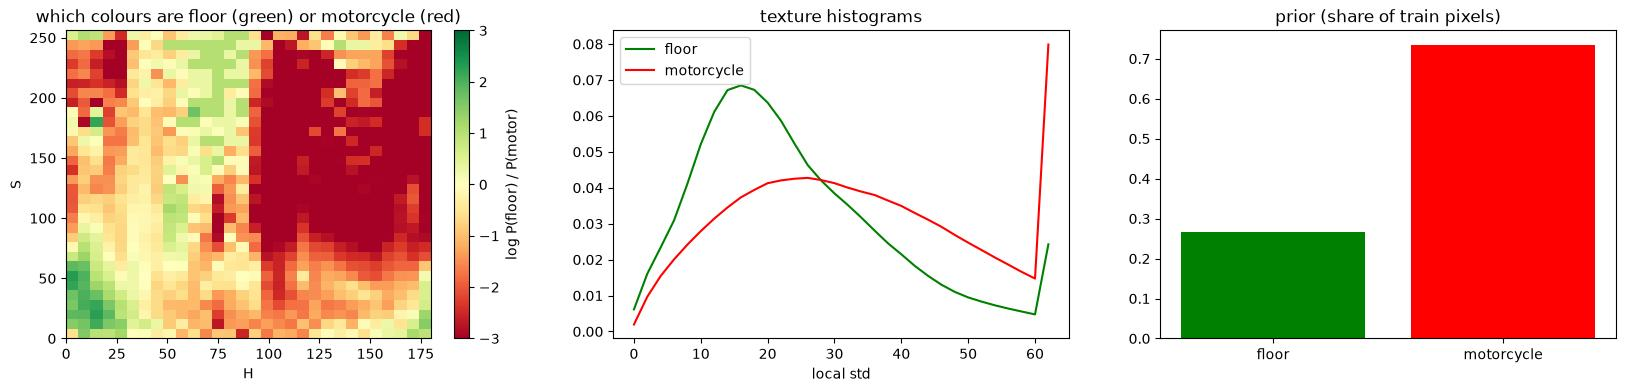

In [18]:
model = fit_histograms('train')
p_hs, p_tex, prior = model

plt.figure(figsize=(20, 4))
plt.subplot(1, 3, 1)
plt.imshow(np.log(p_hs[FLOOR] / p_hs[MOTOR]).T, origin='lower', cmap='RdYlGn', vmin=-3, vmax=3, aspect='auto',
           extent=[0, 180, 0, 256])
plt.colorbar(label='log P(floor) / P(motor)')
plt.xlabel('H')
plt.ylabel('S')
plt.title('which colours are floor (green) or motorcycle (red)')
plt.subplot(1, 3, 2)
plt.plot(np.arange(T_BINS) * 64 / T_BINS, p_tex[FLOOR], color='green', label='floor')
plt.plot(np.arange(T_BINS) * 64 / T_BINS, p_tex[MOTOR], color='red', label='motorcycle')
plt.xlabel('local std')
plt.title('texture histograms')
plt.legend()
plt.subplot(1, 3, 3)
plt.bar(['floor', 'motorcycle'], prior, color=['green', 'red'])
plt.title('prior (share of train pixels)')
plt.show()

In [19]:
def predict(img, roi, model, use_texture, threshold, morphology):
    pred = np.where(log_ratio(img, model, use_texture) > threshold, FLOOR, MOTOR).astype(np.uint8)
    if morphology:
        floor = np.uint8(pred == FLOOR)
        kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (7, 7))
        floor = cv.morphologyEx(floor, cv.MORPH_OPEN, kernel)    # remove small floor specks on motorcycles
        floor = cv.morphologyEx(floor, cv.MORPH_CLOSE, kernel)   # fill small holes in the floor
        pred = np.where(floor == 1, FLOOR, MOTOR).astype(np.uint8)
    pred[roi == 0] = IGNORE
    return pred


def evaluate(preds, idx):
    # IoU per class summed over all frames, plus pixel accuracy
    inter, union, correct, total = np.zeros(2), np.zeros(2), 0, 0
    for p, i in zip(preds, idx):
        valid = Y[i] != IGNORE
        for cls in [FLOOR, MOTOR]:
            inter[cls] += np.sum((p == cls) & (Y[i] == cls) & valid)
            union[cls] += np.sum(((p == cls) | (Y[i] == cls)) & valid)
        correct += np.sum((p == Y[i]) & valid)
        total += np.sum(valid)
    iou = inter / np.maximum(union, 1)
    return {'IoU floor': iou[FLOOR], 'IoU motor': iou[MOTOR], 'mIoU': iou.mean(), 'pixel acc': correct / total}

HS                           best threshold on val = -0.5 (val mIoU 0.703)


HS + texture                 best threshold on val = -1.0 (val mIoU 0.706)


HS + texture + morphology    best threshold on val = -1.5 (val mIoU 0.754)


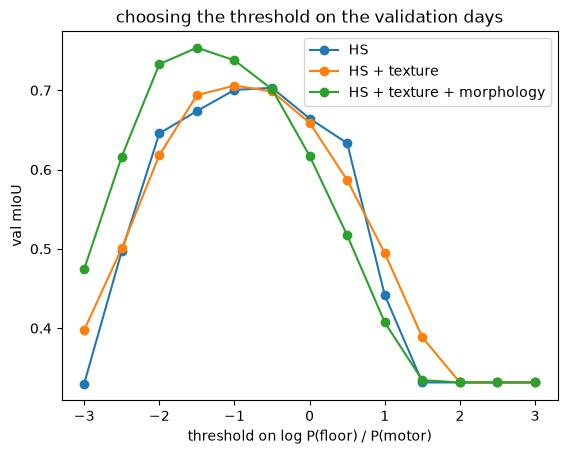

In [20]:
val_idx = np.where(meta['split'] == 'val')[0]
test_idx = np.where(meta['split'] == 'test')[0]


def roi_of(i):
    roi = geo[meta['video_id'][i]]['roi_mask'].copy()
    roi[X[i].max(axis=2) == 0] = 0      # black border left by the alignment warp is not floor (same as notebooks/03)
    return roi


variants = [('HS', False, False), ('HS + texture', True, False), ('HS + texture + morphology', True, True)]
thresholds = np.arange(-3, 3.01, 0.5)

best = {}
for name, use_texture, morphology in variants:
    val_miou = []
    for t in thresholds:
        preds = [predict(X[i], roi_of(i), model, use_texture, t, morphology) for i in val_idx]
        val_miou.append(evaluate(preds, val_idx)['mIoU'])
    best[name] = thresholds[int(np.argmax(val_miou))]
    plt.plot(thresholds, val_miou, 'o-', label=name)
    print(f'{name:28s} best threshold on val = {best[name]:+.1f} (val mIoU {max(val_miou):.3f})')
plt.xlabel('threshold on log P(floor) / P(motor)')
plt.ylabel('val mIoU')
plt.title('choosing the threshold on the validation days')
plt.legend()
plt.show()

In [21]:
results, test_preds = [], {}
for name, use_texture, morphology in variants:
    preds = [predict(X[i], roi_of(i), model, use_texture, best[name], morphology) for i in test_idx]
    test_preds[name] = preds
    r = evaluate(preds, test_idx)
    results.append([name, best[name]] + [round(r[k], 3) for k in ['IoU floor', 'IoU motor', 'mIoU', 'pixel acc']])
results = pd.DataFrame(results, columns=['variant', 'threshold', 'IoU floor', 'IoU motor', 'mIoU', 'pixel acc'])
results

,variant,threshold,IoU floor,IoU motor,mIoU,pixel acc
0,HS,-0.5,0.452,0.726,0.589,0.777
1,HS + texture,-1.0,0.480,0.708,0.594,0.770
2,HS + texture + morphology,-1.5,0.537,0.757,0.647,0.811


sebagai baseline pcd murni (tanpa machine learning yang rumit), setiap piksel diklasifikasi dengan **naive bayes**: dari piksel train dihitung histogram (h, s) dan histogram tekstur untuk lantai dan untuk motor. untuk piksel baru, nilai log P(lantai) − log P(motor) dihitung dari kedua histogram (dianggap independen) ditambah prior nya. kalau nilai nya di atas threshold, piksel dianggap lantai. ini sama dengan **histogram back-projection** yang biasa dipakai di opencv (`cv.calcBackProject`), tapi dengan dua kelas. v tidak dipakai langsung karena paling terpengaruh cahaya, tapi v hasil clahe dipakai untuk menghitung tekstur.

threshold dipilih di hari **val**, lalu ketiga varian dibandingkan di hari **test**:
- **HS**: warna saja
- **HS + texture**: warna dan local std
- **HS + texture + morphology**: ditambah opening (hapus bintik lantai kecil di badan motor) dan closing (tutup lubang kecil di lantai) dengan kernel elips 7 × 7

Step 9: Free Spaces from the Predicted Mask

In [22]:
def count_free_spaces(mask, g):
    floor = (mask == FLOOR).astype(np.uint8)
    floor_bev = cv.warpPerspective(floor, g['H'], g['size'], flags=cv.INTER_NEAREST) * g['roi_bev']
    usable = cv.morphologyEx(floor_bev, cv.MORPH_OPEN, g['kernel'])
    n, labels, comp_stats, _ = cv.connectedComponentsWithStats(usable)
    free = 0
    for c in range(1, n):
        free += max(1, int(round(comp_stats[c, cv.CC_STAT_AREA] / g['motor_area'])))
    return free

In [23]:
free_table = meta.loc[test_idx, ['frame', 'weather', 'free spaces']].rename(columns={'free spaces': 'label'}).reset_index(drop=True)
for name, use_texture, morphology in variants:
    free_table[name] = [count_free_spaces(p, geo[meta['video_id'][i]]) for p, i in zip(test_preds[name], test_idx)]

mae = {name: float(np.mean(np.abs(free_table[name] - free_table['label']))) for name, _, _ in variants}
results['MAE free spaces'] = [round(mae[name], 2) for name, _, _ in variants]
print('MAE of the free-space count on the test days:', {k: round(v, 2) for k, v in mae.items()})
free_table

MAE of the free-space count on the test days: {'HS': 15.12, 'HS + texture': 10.12, 'HS + texture + morphology': 12.77}


,frame,weather,label,HS,HS + texture,HS + texture + morphology
0,20261104_afternoon_dinda_t000.jpg,sunny,30,20,33,56
1,20261104_afternoon_dinda_t015.jpg,sunny,39,25,39,58
2,20261104_afternoon_dinda_t030.jpg,sunny,41,19,36,58
3,20261104_afternoon_dinda_t045.jpg,sunny,44,21,36,63
4,20261104_afternoon_dinda_t060.jpg,sunny,36,22,35,58
5,20261104_afternoon_dinda_t075.jpg,sunny,30,27,37,63
6,20261104_afternoon_dinda_t090.jpg,sunny,25,19,33,53
7,20261104_afternoon_dinda_t105.jpg,sunny,21,14,25,42
8,20261104_afternoon_dinda_t120.jpg,sunny,31,22,37,56
9,20261104_evening_keiza_t000.jpg,dusk,25,2,4,13


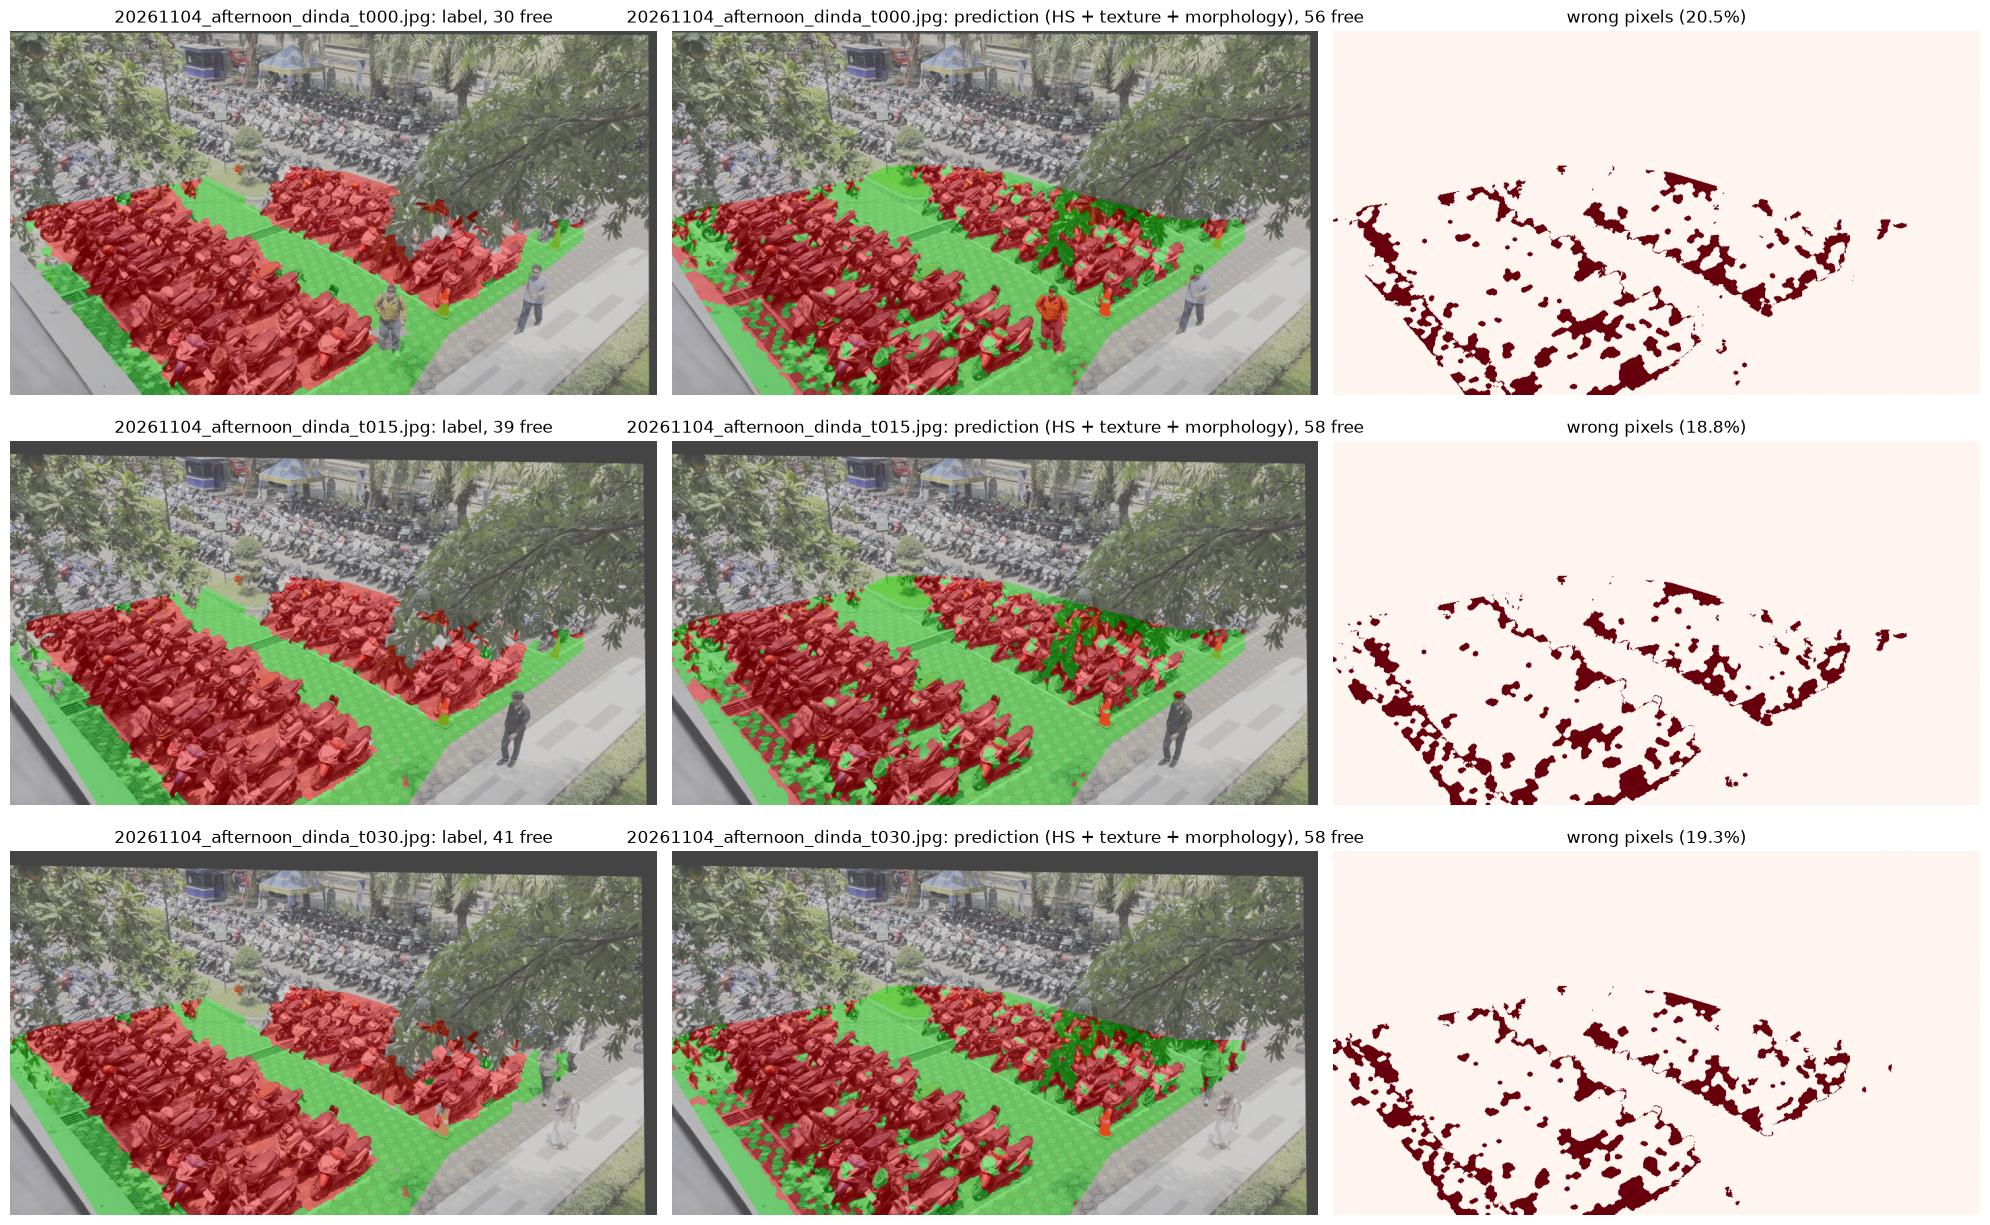

In [24]:
BEST = results.sort_values('mIoU', ascending=False)['variant'].iloc[0]
show = test_idx[:3]

plt.figure(figsize=(20, 4.2 * len(show)))
for r in range(len(show)):
    i = show[r]
    k = list(test_idx).index(i)
    for c, (mask, title) in enumerate([(Y[i], 'label'), (test_preds[BEST][k], f'prediction ({BEST})')]):
        color = np.zeros_like(X[i])
        for cls in CLASS_COLORS:
            color[mask == cls] = CLASS_COLORS[cls]
        plt.subplot(len(show), 3, 3 * r + c + 1)
        plt.imshow(cv.addWeighted(color, 0.45, X[i], 0.55, 0)[:, :, ::-1])
        free = count_free_spaces(mask, geo[meta['video_id'][i]])
        plt.title(f"{meta['frame'][i]}: {title}, {free} free")
        plt.axis('off')
    err = (test_preds[BEST][k] != Y[i]) & (Y[i] != IGNORE)
    plt.subplot(len(show), 3, 3 * r + 3)
    plt.imshow(err, cmap='Reds')
    plt.title(f'wrong pixels ({100 * err.sum() / np.sum(Y[i] != IGNORE):.1f}%)')
    plt.axis('off')
plt.tight_layout()
plt.show()

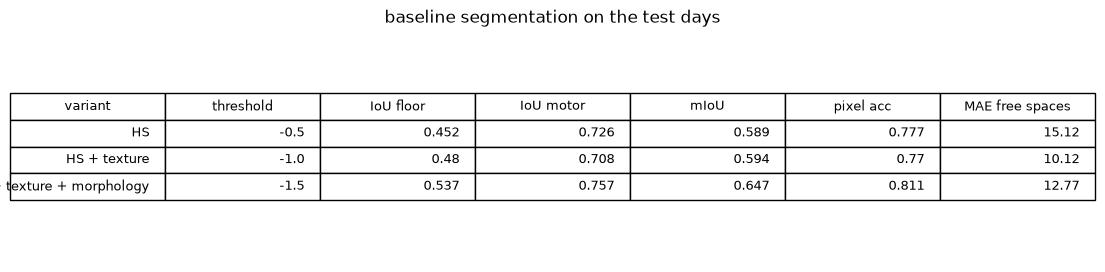

In [25]:
plt.figure(figsize=(14, 3))
table = plt.table(cellText=results.values.tolist(), colLabels=list(results.columns), loc='center')
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.6)
plt.title('baseline segmentation on the test days')
plt.axis('off')
plt.show()

mask prediksi diproses dengan `count_free_spaces` yang sama seperti mask label (bird's-eye view → opening dengan tapak motor → luas ÷ luas satu motor), jadi selain **iou** per piksel, error nya juga bisa diukur dalam satuan yang penting untuk pengguna: **mae jumlah ruang kosong** per frame.

Step 10: Illumination Normalization

In [26]:
from skimage.feature import local_binary_pattern

train_idx = np.where(meta['split'] == 'train')[0]


def roi_pixels(i):
    # ROI without the black border left by the alignment warp: used for colour statistics
    return roi_of(i) > 0


def shades_of_gray(img, mask, p=6):
    # colour constancy: the colour of the light = p-norm mean of every channel (p = 1 gray world, p = inf max-RGB)
    f = img.astype(np.float32)
    illum = np.power(np.mean(f[mask] ** p, axis=0), 1 / p)
    return np.uint8(np.clip(f * illum.mean() / illum, 0, 255))


def channel_cdf(values):
    h = np.bincount(values.ravel(), minlength=256).astype(np.float64)
    return np.cumsum(h) / h.sum()


def lab_reference(gray_world):
    # target distribution: L, a, b of all ROI pixels of the train days (never val / test)
    px = []
    for i in train_idx:
        img = shades_of_gray(X[i], roi_pixels(i)) if gray_world else X[i]
        px.append(cv.cvtColor(img, cv.COLOR_BGR2LAB)[roi_pixels(i)])
    px = np.concatenate(px)
    return [channel_cdf(px[:, c]) for c in range(3)]


REF = {False: lab_reference(False), True: lab_reference(True)}


def hist_match(img, mask, ref):
    # histogram matching in Lab: every channel of the ROI gets the same distribution as the train reference
    lab = cv.cvtColor(img, cv.COLOR_BGR2LAB)
    for c in range(3):
        cdf = channel_cdf(lab[:, :, c][mask])
        lut = np.uint8(np.clip(np.round(np.interp(cdf, ref[c], np.arange(256))), 0, 255))
        lab[:, :, c] = lut[lab[:, :, c]]
    return cv.cvtColor(lab, cv.COLOR_LAB2BGR)


def flat_field(v, sigma=30):
    # single-scale Retinex: brightness / slowly changing illumination = reflectance of the surface
    v = v.astype(np.float32) + 1
    return np.uint8(np.clip(v / cv.GaussianBlur(v, (0, 0), sigma) * 128, 0, 255))


def preprocess(i, light=(), use_clahe=False, denoise=None, **_):
    # PCD for frame i -> HSV uint8. light: 'gray world', 'hist match', 'flat-field' (applied in this order)
    img, mask = X[i], roi_pixels(i)
    if 'gray world' in light:
        img = shades_of_gray(img, mask)
    if 'hist match' in light:
        img = hist_match(img, mask, REF['gray world' in light])
    if denoise == 'bilateral':
        img = cv.bilateralFilter(img, 7, 40, 5)
    hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)
    if 'flat-field' in light:
        hsv[:, :, 2] = flat_field(hsv[:, :, 2])
    if use_clahe:
        hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
    if denoise == 'median':
        hsv[:, :, 2] = cv.medianBlur(hsv[:, :, 2], 5)
    return hsv

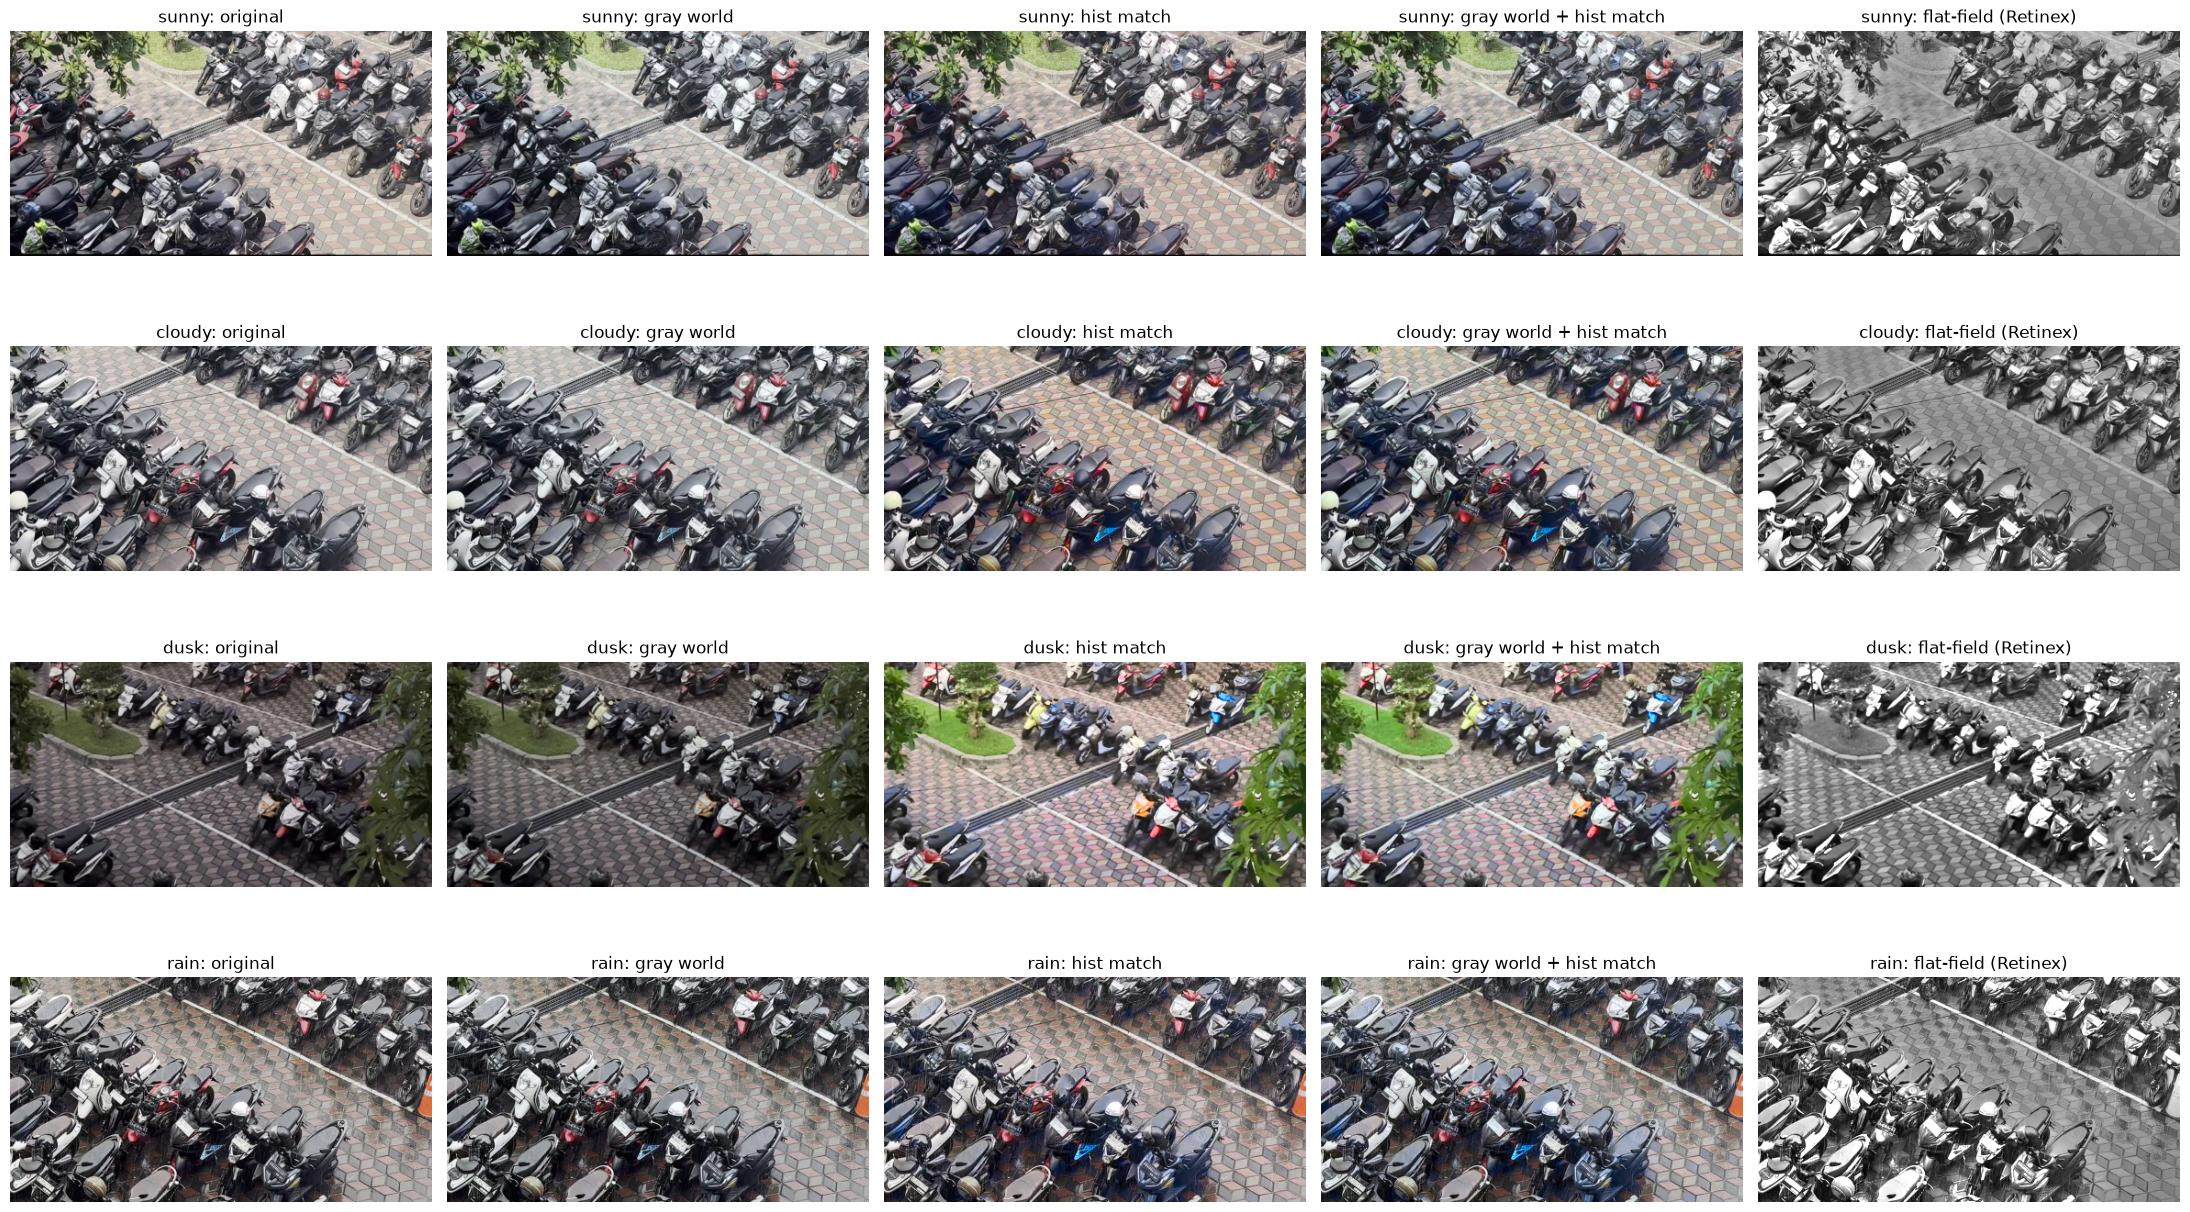

In [27]:
LIGHT = {'original': {}, 'CLAHE on V (step 6)': {'use_clahe': True}, 'gray world': {'light': ('gray world',)},
         'hist match': {'light': ('hist match',)}, 'gray world + hist match': {'light': ('gray world', 'hist match')},
         'flat-field (Retinex)': {'light': ('flat-field',)}}
cond_show = [int(np.argmax(meta['weather'] == w)) for w in conditions]
crop = (slice(y0, y0 + 260), slice(x0, x0 + 460))
cols = [k for k in LIGHT if k != 'CLAHE on V (step 6)']

plt.figure(figsize=(22, 3.3 * len(cond_show)))
for r, i in enumerate(cond_show):
    for c, name in enumerate(cols):
        hsv = preprocess(i, **LIGHT[name])
        plt.subplot(len(cond_show), len(cols), r * len(cols) + c + 1)
        if name == 'flat-field (Retinex)':
            plt.imshow(hsv[:, :, 2][crop], cmap='gray')
        else:
            plt.imshow(cv.cvtColor(hsv, cv.COLOR_HSV2RGB)[crop])
        plt.title(f"{meta['weather'][i]}: {name}")
        plt.axis('off')
plt.tight_layout()
plt.show()

In [28]:
light_rows = []
for name, cfg in LIGHT.items():
    med = {}
    for w in conditions:
        vals = [np.median(preprocess(i, **cfg)[:, :, 2][Y[i] == FLOOR]) for i in np.where(meta['weather'] == w)[0][:6]]
        med[w] = float(np.median(vals))
    fl, mo = {'S': [], 'V': []}, {'S': [], 'V': []}
    for i in train_idx[::2]:
        hsv = preprocess(i, **cfg)
        for k, ch in [('S', 1), ('V', 2)]:
            fl[k].append(hsv[:, :, ch][Y[i] == FLOOR][::50])
            mo[k].append(hsv[:, :, ch][Y[i] == MOTOR][::50])
    light_rows.append([name] + [round(med[w]) for w in conditions] + [round(max(med.values()) - min(med.values()))]
                      + [round(overlap(np.concatenate(fl[k]), np.concatenate(mo[k])), 3) for k in ['V', 'S']])
light_table = pd.DataFrame(light_rows, columns=['method'] + [f'V floor {w}' for w in conditions]
                           + ['spread V', 'overlap V', 'overlap S'])
light_table

,method,V floor sunny,V floor cloudy,V floor dusk,V floor rain,spread V,overlap V,overlap S
0,original,194,188,92,160,102,0.536,0.753
1,CLAHE on V (step 6),192,183,135,164,56,0.645,0.753
2,gray world,190,186,90,158,100,0.538,0.700
3,hist match,182,178,175,163,20,0.516,0.763
4,gray world + hist match,179,175,172,161,18,0.519,0.711
5,flat-field (Retinex),150,152,136,140,16,0.563,0.753


masalah terbesar baseline adalah **cahaya**: lantai yang sama punya median v 194 saat cerah tapi 92 saat dusk (step 5), dan baseline hampir tidak menemukan lantai di video dusk (step 9). clahe (step 6) hanya meratakan kontras **lokal**, jadi tiga teknik normalisasi cahaya **global** dicoba:

- **gray world / shades of gray** (color constancy): warna cahaya diperkirakan dari rata-rata p-norm (p = 6) setiap kanal bgr di dalam roi, lalu setiap kanal dibagi dengan warna cahaya itu. cahaya sore yang kekuningan atau cahaya hujan yang kebiruan jadi netral.
- **histogram matching**: frame diubah ke lab, lalu histogram l, a, b di dalam roi dipaksa sama dengan histogram gabungan **semua frame train** (lewat cdf → lookup table). frame gelap jadi terlihat seperti frame train yang terang. referensi hanya dari train, supaya tidak bocor ke val / test.
- **flat-field (single-scale retinex)**: v dibagi dengan v yang di-blur gaussian (σ = 30). blur besar ≈ pencahayaan yang berubah pelan, jadi hasil bagi nya ≈ pantulan permukaan (reflectance), terlepas dari bayangan gedung.

tabel di atas menunjukkan median v lantai per kondisi (**spread** kecil = lebih tahan cahaya) dan overlap lantai vs motor (kecil = lebih mudah dipisahkan). teknik yang bagus harus menurunkan spread **tanpa** menaikkan overlap terlalu banyak, karena itu kelemahan clahe di step 6.

Step 11: Illumination-Invariant Texture (LBP)

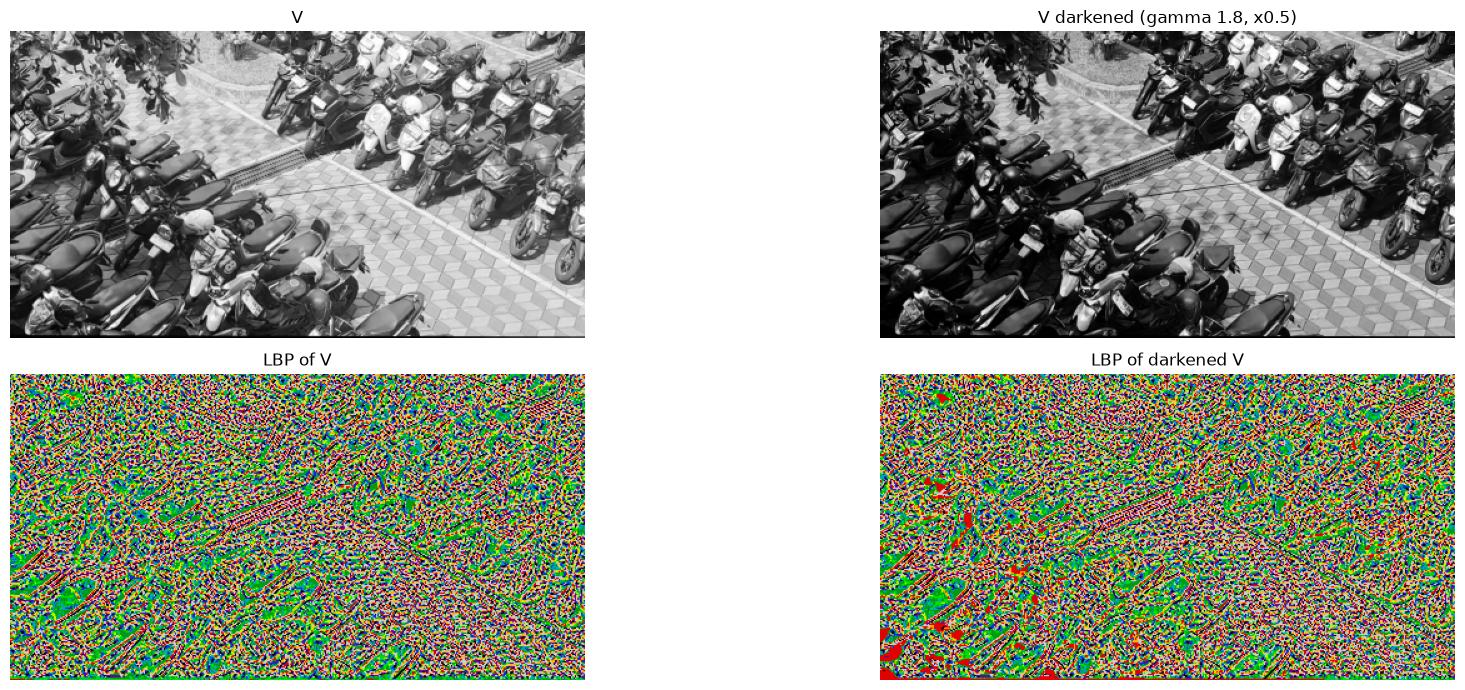

pixels that keep the same value after darkening: V bin 0.4% | local std bin 0.7% | LBP code 86.0%


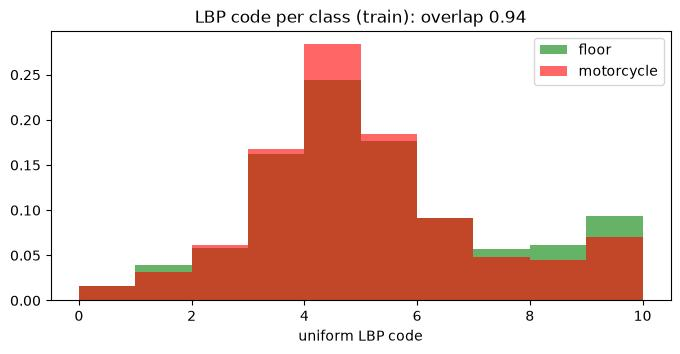

In [29]:
LBP_P, LBP_R = 8, 2


def lbp(v):
    # uniform LBP: 0..P = number of brighter neighbours on a circle of radius R, P + 1 = no regular pattern
    return local_binary_pattern(v, LBP_P, LBP_R, method='uniform').astype(np.uint8)


i = DEMO
v = cv.cvtColor(X[i], cv.COLOR_BGR2HSV)[:, :, 2]
v_dark = np.uint8(np.clip((v / 255.0) ** 1.8 * 0.5 * 255, 0, 255))   # the same frame, dusk-like
roi = Y[i] != IGNORE
same_lbp = np.mean(lbp(v)[roi] == lbp(v_dark)[roi])
same_v = np.mean((v[roi] // 8) == (v_dark[roi] // 8))
std_bin = lambda x: np.minimum(local_std(x).astype(int) * T_BINS // 64, T_BINS - 1)
same_std = np.mean(std_bin(v)[roi] == std_bin(v_dark)[roi])

plt.figure(figsize=(20, 7))
for k, (img_k, title) in enumerate([(v, 'V'), (v_dark, 'V darkened (gamma 1.8, x0.5)'),
                                    (lbp(v), 'LBP of V'), (lbp(v_dark), 'LBP of darkened V')]):
    plt.subplot(2, 2, k + 1)
    plt.imshow(img_k[crop], cmap='gray' if k < 2 else 'nipy_spectral')
    plt.title(title)
    plt.axis('off')
plt.tight_layout()
plt.show()
print(f'pixels that keep the same value after darkening: V bin {100 * same_v:.1f}% | '
      f'local std bin {100 * same_std:.1f}% | LBP code {100 * same_lbp:.1f}%')

lbp_floor, lbp_motor = [], []
for i in train_idx:
    code_i = lbp(cv.medianBlur(cv.cvtColor(X[i], cv.COLOR_BGR2HSV)[:, :, 2], 5))
    lbp_floor.append(code_i[Y[i] == FLOOR][::20])
    lbp_motor.append(code_i[Y[i] == MOTOR][::20])
lbp_floor, lbp_motor = np.concatenate(lbp_floor), np.concatenate(lbp_motor)
ov = overlap(lbp_floor, lbp_motor, bins=LBP_P + 2, value_range=(0, LBP_P + 2))
plt.figure(figsize=(8, 3.5))
plt.hist(lbp_floor, bins=LBP_P + 2, range=(0, LBP_P + 2), density=True, alpha=0.6, color='green', label='floor')
plt.hist(lbp_motor, bins=LBP_P + 2, range=(0, LBP_P + 2), density=True, alpha=0.6, color='red', label='motorcycle')
plt.xlabel('uniform LBP code')
plt.title(f'LBP code per class (train): overlap {ov:.2f}')
plt.legend()
plt.show()

**lbp (local binary pattern)** membandingkan setiap piksel dengan 8 tetangga di lingkaran radius 2: tetangga yang lebih terang diberi 1, yang lebih gelap 0. versi *uniform* menghitung berapa tetangga yang lebih terang (0–8), dan kode 9 untuk pola yang tidak teratur. karena yang dipakai hanya **lebih terang atau lebih gelap**, kode lbp tidak berubah kalau seluruh gambar digelapkan atau diterangkan (perubahan monoton). angka di atas membandingkan berapa persen piksel yang nilai nya tetap sama setelah frame digelapkan seperti dusk: v hampir semua berubah, local std juga banyak berubah, sedangkan lbp jauh lebih stabil.

di step 12 lbp dicoba sebagai fitur tekstur **tambahan** di samping local std.

Step 12: Preprocessing Comparison

In [30]:
VARIANTS = {
    'raw (HSV, no PCD)':                         dict(),
    'median':                                    dict(denoise='median'),
    'CLAHE + median (step 8)':                   dict(use_clahe=True, denoise='median'),
    'CLAHE + bilateral':                         dict(use_clahe=True, denoise='bilateral'),
    'flat-field + median':                       dict(light=('flat-field',), denoise='median'),
    'gray world + median':                       dict(light=('gray world',), denoise='median'),
    'hist match + median':                       dict(light=('hist match',), denoise='median'),
    'gray world + hist match + median':          dict(light=('gray world', 'hist match'), denoise='median'),
    'gray world + hist match + CLAHE + median':  dict(light=('gray world', 'hist match'), use_clahe=True, denoise='median'),
    'gray world + hist match + median + LBP':    dict(light=('gray world', 'hist match'), denoise='median', lbp=True),
}
OLD = 'CLAHE + median (step 8)'


def nb_features(i, cfg):
    hsv = preprocess(i, **cfg)
    h_bin = np.minimum(hsv[:, :, 0].astype(int) * H_BINS // 180, H_BINS - 1)
    s_bin = np.minimum(hsv[:, :, 1].astype(int) * S_BINS // 256, S_BINS - 1)
    tex = [np.minimum(local_std(hsv[:, :, 2]).astype(int) * T_BINS // 64, T_BINS - 1)]
    if cfg.get('lbp'):
        tex.append(lbp(hsv[:, :, 2]))
    return h_bin, s_bin, tex


def fit_nb(cfg):
    # same naive Bayes as step 8 (H, S histogram + texture histograms), only the PCD in front of it changes
    hs = np.ones((2, H_BINS, S_BINS))
    tex = None
    for i in train_idx:
        h_bin, s_bin, t = nb_features(i, cfg)
        tex = tex or [np.ones((2, T_BINS)) for _ in t]
        for cls in [FLOOR, MOTOR]:
            m = Y[i] == cls
            np.add.at(hs[cls], (h_bin[m], s_bin[m]), 1)
            for k in range(len(t)):
                np.add.at(tex[k][cls], t[k][m], 1)
    prior = np.array([hs[FLOOR].sum(), hs[MOTOR].sum()])
    return hs / hs.sum(axis=(1, 2), keepdims=True), [t / t.sum(axis=1, keepdims=True) for t in tex], prior / prior.sum()


def nb_score(i, model, cfg):
    p_hs, p_tex, prior = model
    h_bin, s_bin, t = nb_features(i, cfg)
    score = np.log(p_hs[FLOOR][h_bin, s_bin] / p_hs[MOTOR][h_bin, s_bin]) + np.log(prior[FLOOR] / prior[MOTOR])
    for k in range(len(t)):
        score += np.log(p_tex[k][FLOOR][t[k]] / p_tex[k][MOTOR][t[k]])
    return score


KERNEL = cv.getStructuringElement(cv.MORPH_ELLIPSE, (7, 7))


def to_mask(score, roi, threshold):
    # threshold + opening / closing, as 'HS + texture + morphology' in step 8
    floor = np.uint8(score > threshold)
    floor = cv.morphologyEx(cv.morphologyEx(floor, cv.MORPH_OPEN, KERNEL), cv.MORPH_CLOSE, KERNEL)
    pred = np.where(floor == 1, FLOOR, MOTOR).astype(np.uint8)
    pred[roi == 0] = IGNORE
    return pred


def confusion(preds, idx):
    # rows = label (floor, motorcycle), columns = prediction, in pixels
    cm = np.zeros((2, 2), np.int64)
    for p, i in zip(preds, idx):
        valid = Y[i] != IGNORE
        for a in [FLOOR, MOTOR]:
            for b in [FLOOR, MOTOR]:
                cm[a, b] += np.sum((Y[i] == a) & (p == b) & valid)
    return cm


def cm_metrics(cm):
    out = {}
    for cls, n in [(FLOOR, 'floor'), (MOTOR, 'motor')]:
        tp, fp, fn = cm[cls, cls], cm[:, cls].sum() - cm[cls, cls], cm[cls].sum() - cm[cls, cls]
        out[f'precision {n}'] = tp / max(tp + fp, 1)
        out[f'recall {n}'] = tp / max(tp + fn, 1)
        out[f'F1 {n}'] = 2 * tp / max(2 * tp + fp + fn, 1)
        out[f'IoU {n}'] = tp / max(tp + fp + fn, 1)
    out['mIoU'] = (out['IoU floor'] + out['IoU motor']) / 2
    out['pixel acc'] = np.trace(cm) / cm.sum()
    return out


def free_mae(preds, idx):
    err = np.array([abs(count_free_spaces(p, geo[meta['video_id'][i]]) - meta['free spaces'][i]) for p, i in zip(preds, idx)])
    return err.mean(), err

In [31]:
thresholds_fine = np.arange(-3, 3.01, 0.25)
compare, PRED, ERR = [], {}, {}
test_vid = meta['video_id'].values[test_idx]

for name, cfg in VARIANTS.items():
    t0 = time.time()
    model = fit_nb(cfg)
    val_scores = {i: nb_score(i, model, cfg) for i in val_idx}
    val_miou = [cm_metrics(confusion([to_mask(val_scores[i], roi_of(i), t) for i in val_idx], val_idx))['mIoU']
                for t in thresholds_fine]
    thr = float(thresholds_fine[int(np.argmax(val_miou))])                     # threshold chosen on val
    val_preds = [to_mask(val_scores[i], roi_of(i), thr) for i in val_idx]
    PRED[name] = [to_mask(nb_score(i, model, cfg), roi_of(i), thr) for i in test_idx]
    m = cm_metrics(confusion(PRED[name], test_idx))
    mae, ERR[name] = free_mae(PRED[name], test_idx)
    row = {'variant': name, 'threshold': thr, 'val mIoU': max(val_miou), 'val MAE': free_mae(val_preds, val_idx)[0],
           'test mIoU': m['mIoU'], 'IoU floor': m['IoU floor'], 'IoU motor': m['IoU motor'],
           'pixel acc': m['pixel acc'], 'F1 floor': m['F1 floor'], 'test MAE': mae}
    for v in np.unique(test_vid):
        row[f"MAE {v[9:]} ({meta.loc[meta['video_id'] == v, 'weather'].iloc[0]})"] = ERR[name][test_vid == v].mean()
    compare.append(row)
    print(f'{name:42s} {time.time() - t0:4.0f} s')

compare = pd.DataFrame(compare).round(3)
# the final output is the number of free spaces, so the PCD is chosen by the lowest MAE on the VALIDATION days
CHOSEN = compare.sort_values(['val MAE', 'val mIoU'], ascending=[True, False])['variant'].iloc[0]
print('\nchosen on val:', CHOSEN)
compare

raw (HSV, no PCD)                            12 s


median                                       11 s


CLAHE + median (step 8)                      11 s


CLAHE + bilateral                            12 s


flat-field + median                          14 s


gray world + median                          13 s


hist match + median                          12 s


gray world + hist match + median             15 s


gray world + hist match + CLAHE + median     15 s


gray world + hist match + median + LBP       20 s

chosen on val: gray world + hist match + CLAHE + median


,variant,threshold,val mIoU,val MAE,test mIoU,IoU floor,IoU motor,pixel acc,F1 floor,test MAE,MAE afternoon_dinda (sunny),MAE evening_keiza (dusk),MAE morning_keiza (sunny)
0,"raw (HSV, no PCD)",-1.50,0.763,3.692,0.695,0.594,0.796,0.843,0.745,7.269,13.222,3.444,4.875
1,median,-1.50,0.769,3.462,0.681,0.577,0.786,0.834,0.732,8.231,14.000,5.667,4.625
2,CLAHE + median (step 8),-1.50,0.754,3.769,0.647,0.537,0.757,0.811,0.699,12.769,23.333,10.778,3.125
3,CLAHE + bilateral,-1.50,0.750,3.462,0.641,0.534,0.748,0.805,0.696,11.692,24.778,7.111,2.125
4,flat-field + median,-1.25,0.771,3.846,0.695,0.576,0.813,0.851,0.731,11.654,14.667,14.333,5.250
5,gray world + median,-1.75,0.767,3.154,0.679,0.577,0.782,0.832,0.731,7.423,12.556,3.778,5.750
6,hist match + median,-1.50,0.759,3.923,0.657,0.537,0.778,0.823,0.699,5.808,7.222,6.000,4.000
7,gray world + hist match + median,-1.50,0.762,4.692,0.668,0.548,0.788,0.831,0.708,6.038,7.778,5.222,5.000
8,gray world + hist match + CLAHE + median,-1.75,0.756,2.769,0.648,0.533,0.763,0.813,0.695,8.154,17.667,3.667,2.500
9,gray world + hist match + median + LBP,-1.50,0.763,4.692,0.669,0.550,0.789,0.832,0.709,6.038,7.222,5.667,5.125


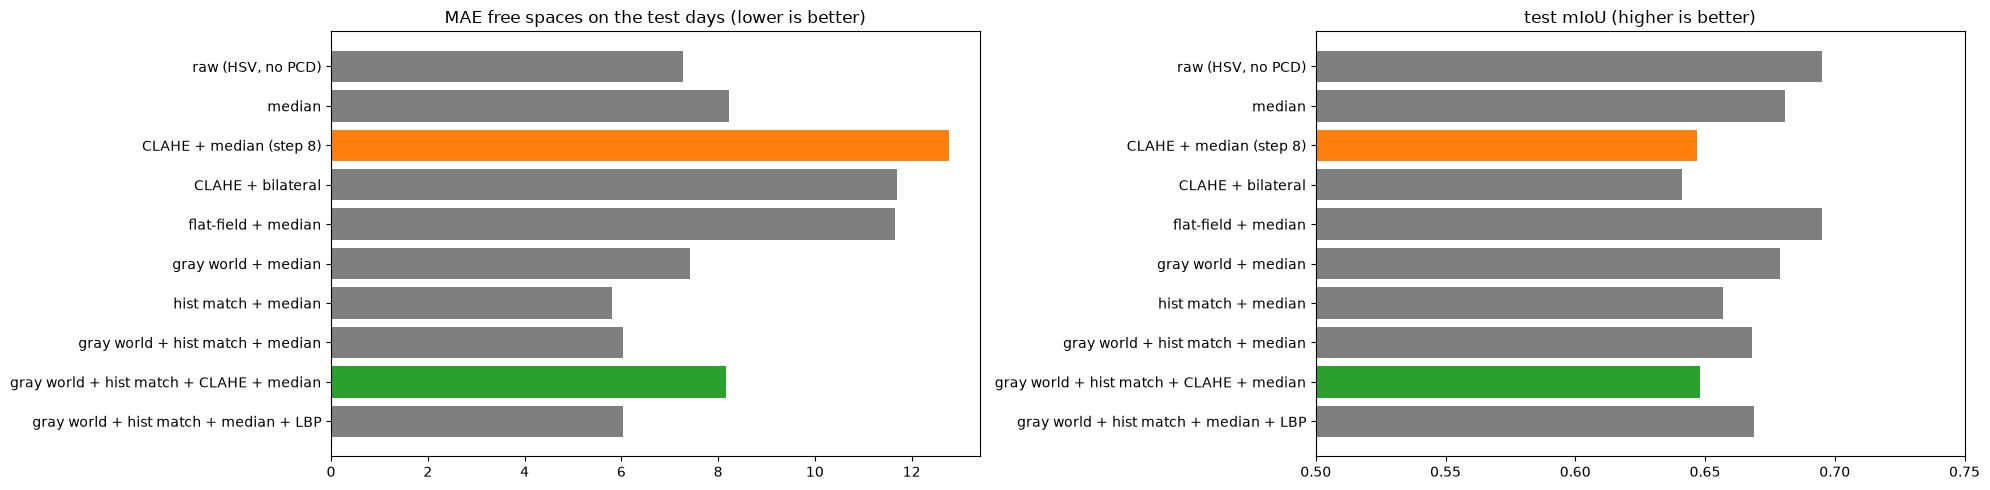

saved C:\Users\ASUS\.vscode\pcd\project-akhir\results\pcd_eval\preprocessing_comparison.csv


In [32]:
order = compare.set_index('variant')
fig, ax = plt.subplots(1, 2, figsize=(20, 5))
colors = ['tab:green' if v == CHOSEN else 'tab:orange' if v == OLD else 'tab:gray' for v in order.index]
ax[0].barh(order.index, order['test MAE'], color=colors)
ax[0].set_title('MAE free spaces on the test days (lower is better)')
ax[0].invert_yaxis()
ax[1].barh(order.index, order['test mIoU'], color=colors)
ax[1].set_xlim(0.5, 0.75)
ax[1].set_title('test mIoU (higher is better)')
ax[1].invert_yaxis()
plt.tight_layout()
plt.show()

OUT_DIR = ROOT / 'results' / 'pcd_eval'
OUT_DIR.mkdir(parents=True, exist_ok=True)
compare.to_csv(OUT_DIR / 'preprocessing_comparison.csv', index=False)
print('saved', OUT_DIR / 'preprocessing_comparison.csv')

semua varian memakai **model, fitur, split dan post-processing yang sama** (naive bayes h, s + local std + morphology dari step 8), dan yang berbeda hanya pcd di depan nya. jadi selisih skor nya murni efek preprocessing.

aturan pemilihan supaya adil:
1. threshold setiap varian dipilih dari **val mIoU**.
2. varian pcd dipilih dari **val MAE** (jumlah ruang kosong adalah output akhir yang dilihat pengguna), kalau sama dipilih yang val mIoU nya lebih tinggi.
3. kolom test hanya **dilaporkan**, tidak dipakai untuk memilih.

batang hijau adalah varian yang terpilih, oranye adalah pcd lama (step 8).

Step 13: Evaluation of the Chosen PCD (Confusion Matrix)

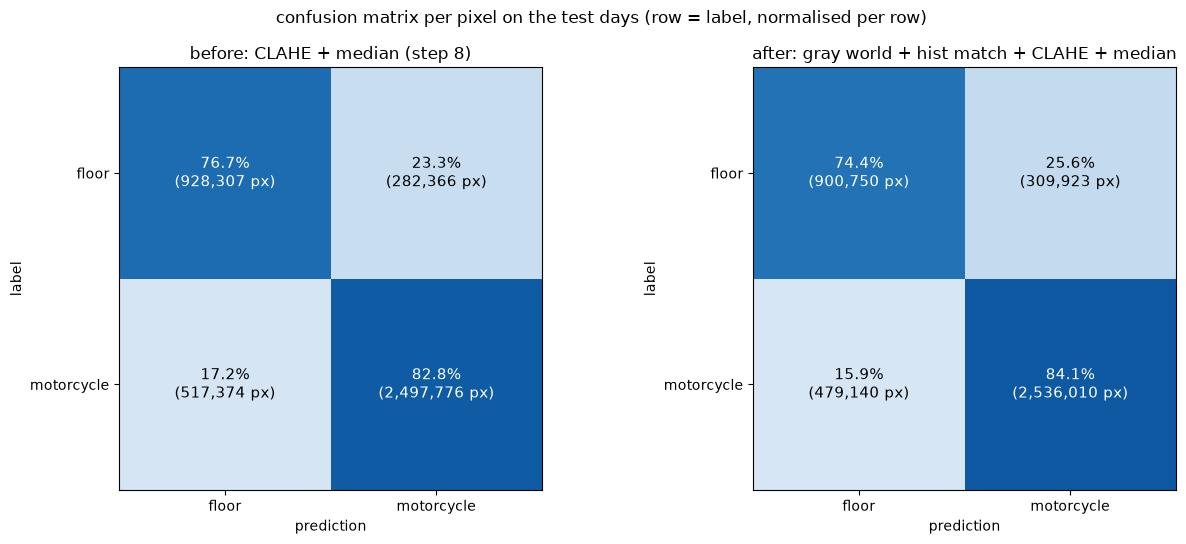

,precision floor,recall floor,F1 floor,IoU floor,precision motor,recall motor,F1 motor,IoU motor,mIoU,pixel acc,MAE free spaces
CLAHE + median (step 8),0.642,0.767,0.699,0.537,0.898,0.828,0.862,0.757,0.647,0.811,12.77
gray world + hist match + CLAHE + median,0.653,0.744,0.695,0.533,0.891,0.841,0.865,0.763,0.648,0.813,8.15


In [33]:
def plot_cm(ax, cm, title):
    norm = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(norm, cmap='Blues', vmin=0, vmax=1)
    for a in range(2):
        for b in range(2):
            ax.text(b, a, f'{100 * norm[a, b]:.1f}%\n({cm[a, b]:,} px)', ha='center', va='center',
                    color='white' if norm[a, b] > 0.5 else 'black', fontsize=11)
    ax.set_xticks([0, 1], ['floor', 'motorcycle'])
    ax.set_yticks([0, 1], ['floor', 'motorcycle'])
    ax.set_xlabel('prediction')
    ax.set_ylabel('label')
    ax.set_title(title)


CM = {name: confusion(PRED[name], test_idx) for name in [OLD, CHOSEN]}
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
plot_cm(ax[0], CM[OLD], f'before: {OLD}')
plot_cm(ax[1], CM[CHOSEN], f'after: {CHOSEN}')
plt.suptitle('confusion matrix per pixel on the test days (row = label, normalised per row)')
plt.tight_layout()
plt.savefig(OUT_DIR / 'confusion_matrix_test.jpg', dpi=110)
plt.show()

per_class = pd.DataFrame({name: cm_metrics(CM[name]) for name in [OLD, CHOSEN]}).T.round(3)
per_class['MAE free spaces'] = [round(float(ERR[n].mean()), 2) for n in [OLD, CHOSEN]]
per_class

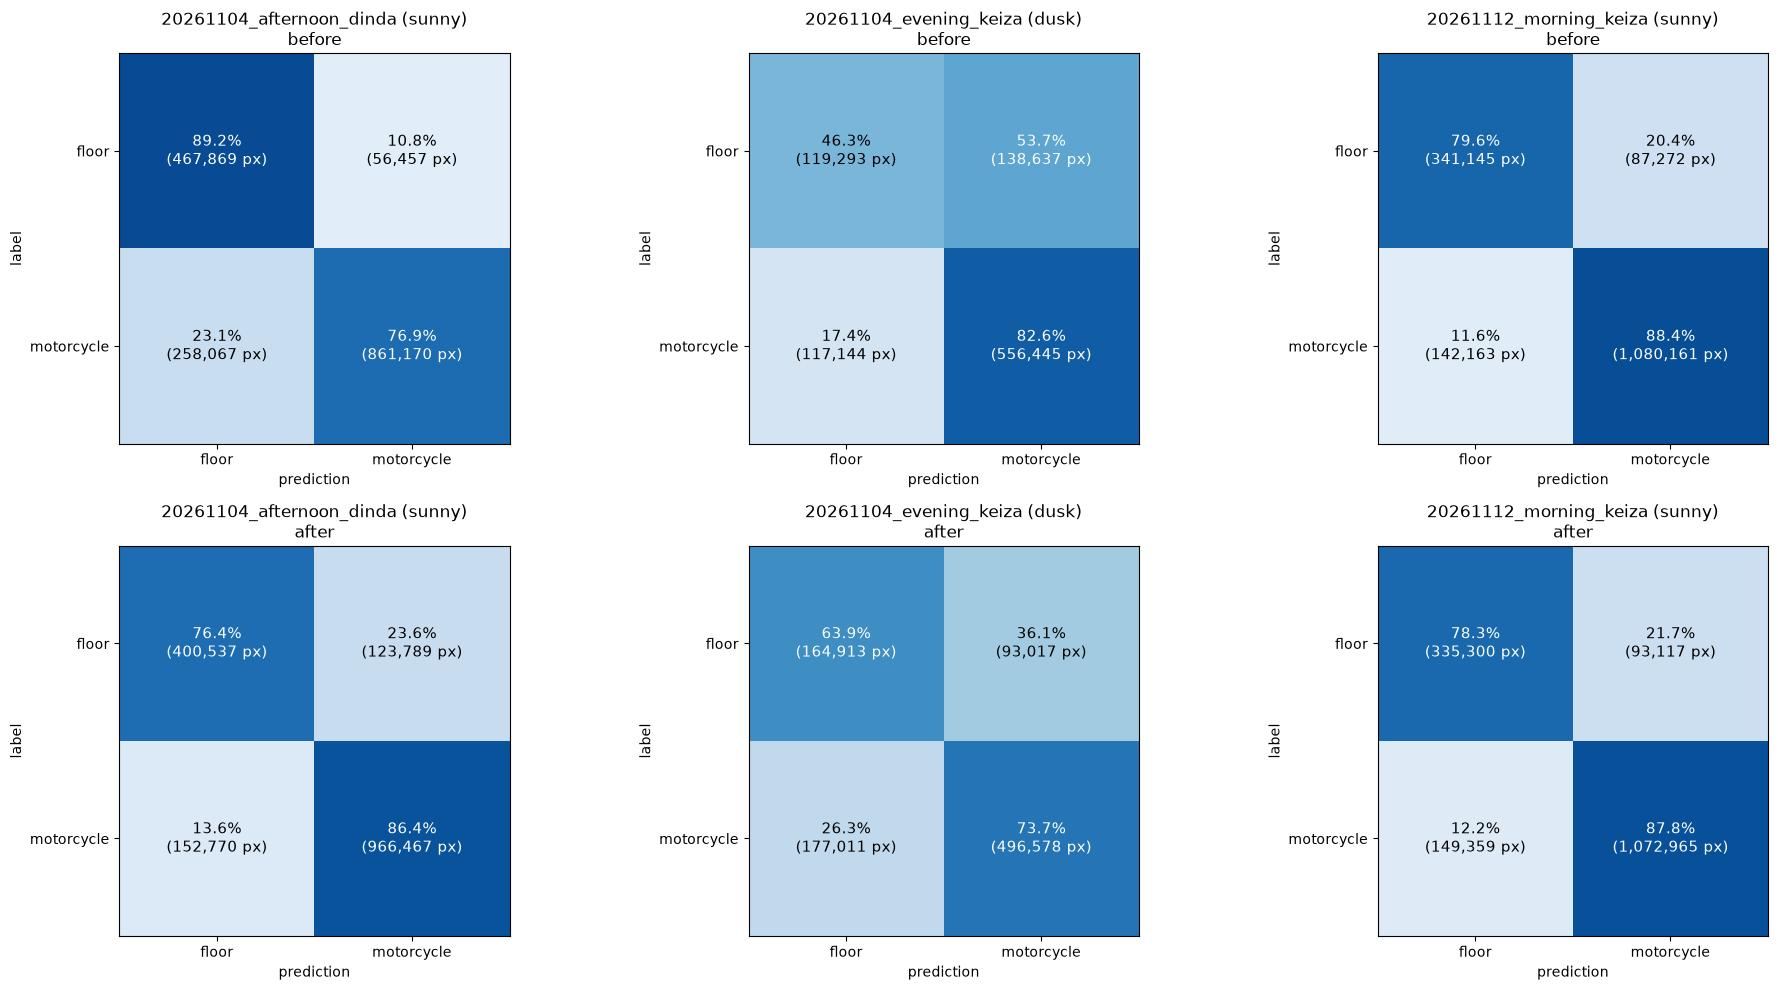

,video,weather,PCD,IoU floor,mIoU,pixel acc,mean label free spaces,MAE free spaces
0,20261104_afternoon_dinda,sunny,CLAHE + median (step 8),0.598,0.665,0.809,33.0,23.33
1,20261104_afternoon_dinda,sunny,gray world + hist match + CLAHE + median,0.592,0.685,0.832,33.0,17.67
2,20261104_evening_keiza,dusk,CLAHE + median (step 8),0.318,0.502,0.725,19.0,10.78
3,20261104_evening_keiza,dusk,gray world + hist match + CLAHE + median,0.379,0.513,0.710,19.0,3.67
4,20261112_morning_keiza,sunny,CLAHE + median (step 8),0.598,0.711,0.861,14.9,3.12
5,20261112_morning_keiza,sunny,gray world + hist match + CLAHE + median,0.580,0.698,0.853,14.9,2.50


In [34]:
videos = list(np.unique(test_vid))
fig, ax = plt.subplots(2, len(videos), figsize=(6.5 * len(videos), 10))
per_video = []
for c, v in enumerate(videos):
    sel = np.where(test_vid == v)[0]
    w = meta.loc[meta['video_id'] == v, 'weather'].iloc[0]
    for r, name in enumerate([OLD, CHOSEN]):
        cm = confusion([PRED[name][k] for k in sel], test_idx[sel])
        plot_cm(ax[r, c], cm, f"{v} ({w})\n{'before' if r == 0 else 'after'}")
        mt = cm_metrics(cm)
        per_video.append([v, w, name, round(mt['IoU floor'], 3), round(mt['mIoU'], 3), round(mt['pixel acc'], 3),
                          round(float(meta['free spaces'].values[test_idx[sel]].mean()), 1),
                          round(float(ERR[name][sel].mean()), 2)])
plt.tight_layout()
plt.savefig(OUT_DIR / 'confusion_matrix_per_video.jpg', dpi=100)
plt.show()
pd.DataFrame(per_video, columns=['video', 'weather', 'PCD', 'IoU floor', 'mIoU', 'pixel acc',
                                 'mean label free spaces', 'MAE free spaces'])

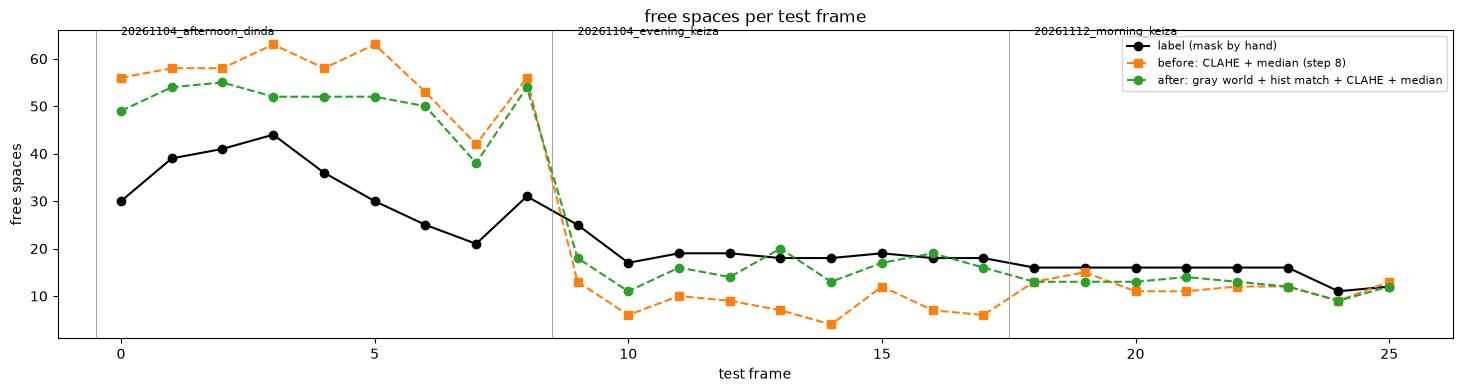

In [35]:
pred_free = {n: [count_free_spaces(p, geo[meta['video_id'][i]]) for p, i in zip(PRED[n], test_idx)] for n in [OLD, CHOSEN]}
label_free = meta['free spaces'].values[test_idx]

plt.figure(figsize=(18, 4))
x = np.arange(len(test_idx))
plt.plot(x, label_free, 'ko-', label='label (mask by hand)')
plt.plot(x, pred_free[OLD], 's--', color='tab:orange', label=f'before: {OLD}')
plt.plot(x, pred_free[CHOSEN], 'o--', color='tab:green', label=f'after: {CHOSEN}')
for v in videos:
    first = int(np.where(test_vid == v)[0][0])
    plt.axvline(first - 0.5, color='gray', lw=0.5)
    plt.text(first, max(label_free.max(), max(pred_free[OLD])) + 2, v, fontsize=8)
plt.xlabel('test frame')
plt.ylabel('free spaces')
plt.title('free spaces per test frame')
plt.legend(loc='upper right', fontsize=8)
plt.show()

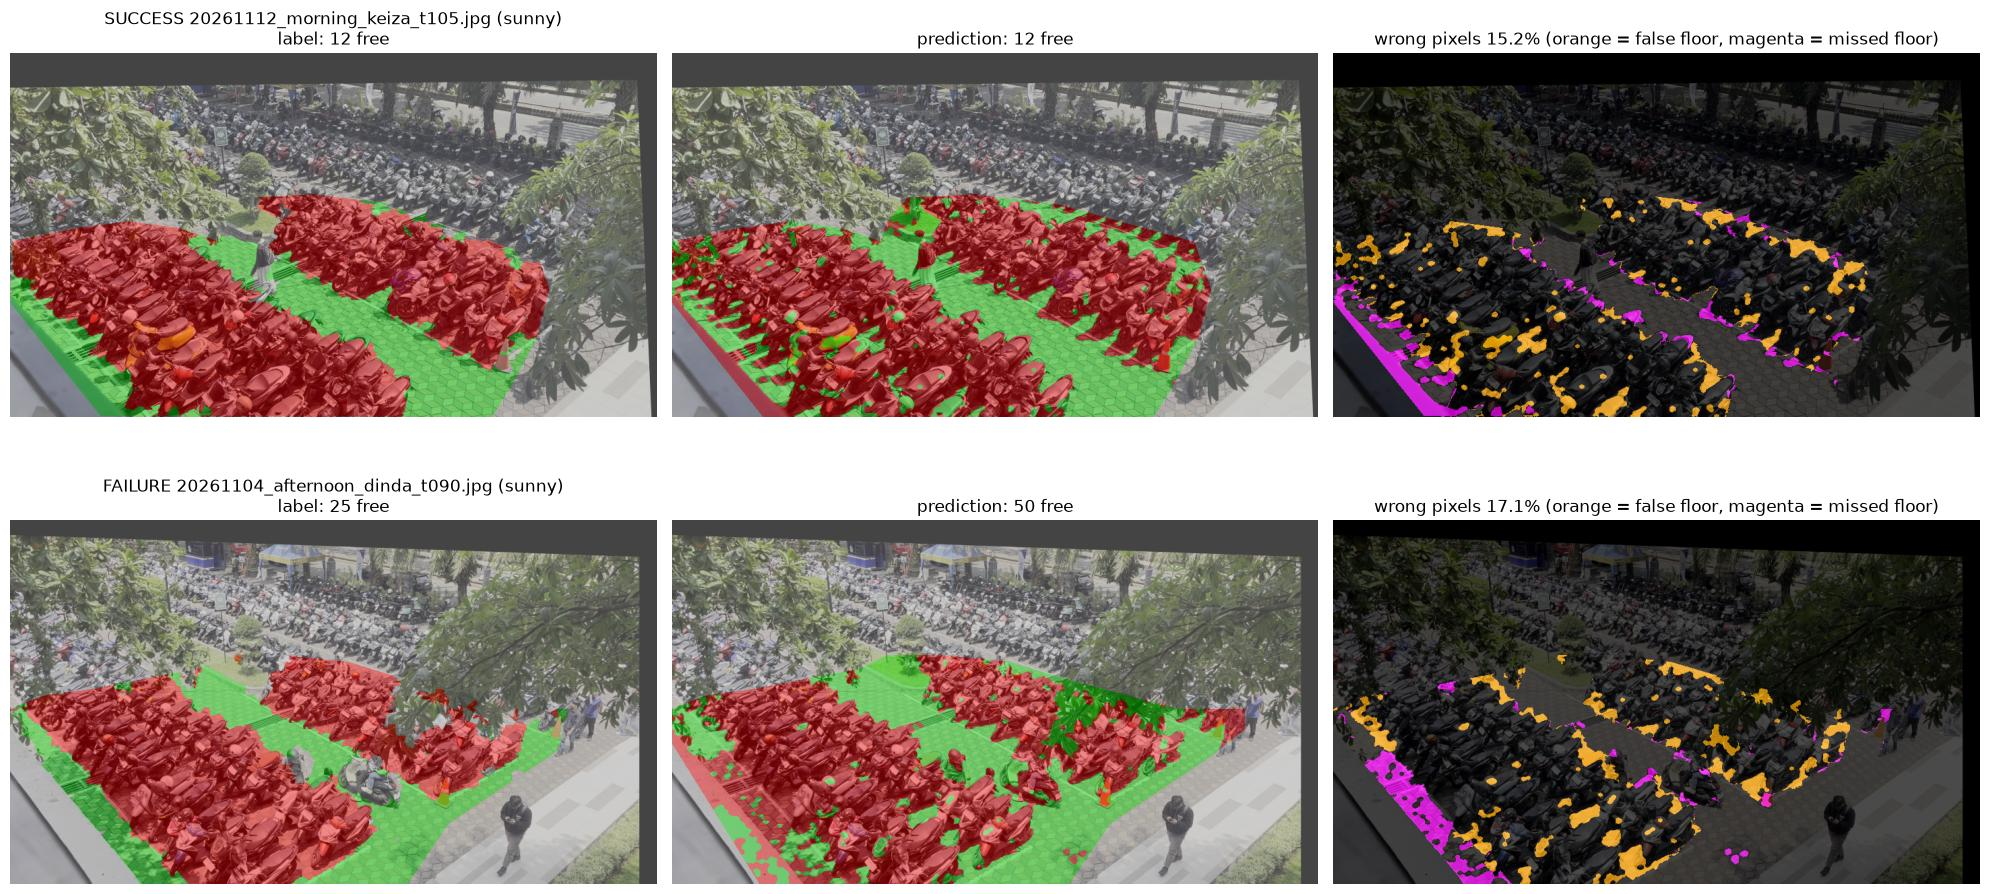

In [36]:
def overlay(i, mask):
    color = np.zeros_like(X[i])
    for cls in CLASS_COLORS:
        color[mask == cls] = CLASS_COLORS[cls]
    return cv.addWeighted(color, 0.45, X[i], 0.55, 0)[:, :, ::-1]


err_new = ERR[CHOSEN]
cases = [('success', int(np.argmin(err_new + 0.01 * np.arange(len(err_new))))), ('failure', int(np.argmax(err_new)))]
plt.figure(figsize=(20, 5 * len(cases)))
for r, (kind, k) in enumerate(cases):
    i = test_idx[k]
    pred = PRED[CHOSEN][k]
    wrong = (pred != Y[i]) & (Y[i] != IGNORE)
    err_vis = np.zeros_like(X[i])
    err_vis[(pred == FLOOR) & (Y[i] == MOTOR)] = (0, 165, 255)   # orange: motorcycle predicted as floor (false free)
    err_vis[(pred == MOTOR) & (Y[i] == FLOOR)] = (255, 0, 255)   # magenta: floor predicted as motorcycle (missed free)
    panels = [(overlay(i, Y[i]), f'label: {label_free[k]} free'),
              (overlay(i, pred), f'prediction: {pred_free[CHOSEN][k]} free'),
              (cv.addWeighted(err_vis, 0.7, X[i], 0.3, 0)[:, :, ::-1],
               f'wrong pixels {100 * wrong.sum() / np.sum(Y[i] != IGNORE):.1f}% (orange = false floor, magenta = missed floor)')]
    for c, (img_k, title) in enumerate(panels):
        plt.subplot(len(cases), 3, 3 * r + c + 1)
        plt.imshow(img_k)
        plt.title(f"{kind.upper()} {meta['frame'][i]} ({meta['weather'][i]})\n{title}" if c == 0 else title)
        plt.axis('off')
plt.tight_layout()
plt.savefig(OUT_DIR / 'success_failure.jpg', dpi=90)
plt.show()

**confusion matrix** dihitung per piksel di dalam roi pada hari test. baris = label, kolom = prediksi, dan setiap baris dinormalisasi:

- **floor → floor** (kiri atas): recall lantai, yaitu persentase lantai kosong yang ditemukan.
- **floor → motorcycle** (kanan atas): lantai kosong yang terlewat, jadi ruang kosong terhitung terlalu sedikit.
- **motorcycle → floor** (kiri bawah): motor yang dikira lantai, jadi ruang kosong terhitung terlalu banyak. kesalahan ini paling merugikan pengguna, karena mereka diarahkan ke tempat yang ternyata penuh.
- **motorcycle → motorcycle** (kanan bawah): recall motor.

confusion matrix per video menunjukkan di kondisi mana model gagal. contoh **success** dan **failure** di atas adalah frame test dengan error jumlah ruang kosong terkecil dan terbesar.

Step 14: Problem Analysis

ringkasan masalah yang ditemukan dari step 5–13 (angka dari run ini):

**1. cahaya adalah sumber error terbesar, terutama dusk.** median v lantai turun dari 194 (cerah) ke 92 (dusk), dan train tidak punya frame dusk. dengan pcd lama (clahe + median) mae ruang kosong di video dusk 10.8. setelah **gray world + histogram matching**, spread v antar kondisi turun dari 102 ke 18, mae dusk turun ke 3.7, dan iou lantai dusk naik dari 0.32 ke 0.38.

**2. clahe punya trade-off.** clahe meratakan kontras lokal, tapi overlap v lantai vs motor naik dari 0.54 ke 0.65, dan pada model yang sama varian **tanpa** clahe (raw, test mIoU 0.695) justru lebih baik daripada clahe + median (0.647). histogram matching menurunkan spread tanpa menaikkan overlap (0.52), jadi normalisasi cahaya global lebih cocok daripada equalization lokal untuk masalah ini.

**3. hue tidak bisa diandalkan.** 82.8% piksel lantai punya s < 40, jadi h nya acak. h harus dipakai bersama s (histogram 2d h × s), dan gray world membantu karena membuat paving yang abu-abu benar-benar netral (overlap s turun dari 0.75 ke 0.70).

**4. lbp stabil tapi tidak menambah skor di naive bayes.** 86% kode lbp tetap sama setelah frame digelapkan (v hanya 0.4%), tapi menambahkan lbp tidak mengubah mae. naive bayes menganggap fitur saling independen, sedangkan lbp dan local std sama-sama mengukur tekstur, jadi informasinya dobel. lbp lebih berguna sebagai input model yang bisa menggabungkan fitur, misalnya random forest / xgboost di notebook 03.

**5. error utama sekarang: motor dihitung lantai (false floor).** di confusion matrix, 15.9% piksel motor diprediksi lantai dan 25.6% lantai diprediksi motor. contoh failure (20261104_afternoon_dinda, label 25, prediksi 50) memperlihatkan dari mana asalnya: celah gelap di antara motor, bayangan dan daun pohon di kanan atas, serta jok motor yang abu-abu. setelah opening di bird's-eye view, potongan ini masih cukup besar untuk dihitung sebagai ruang kosong, jadi jumlahnya terlalu banyak. sebaliknya, garis putih dan tepi lantai di kiri bawah sering dianggap motor (missed floor).

**6. hari validasi terlalu kecil untuk memilih pcd dengan yakin.** val hanya 13 frame dari 2 video, dan val mae semua varian berdekatan (2.8–4.7), sedangkan test mae nya berbeda jauh (5.8–12.8). varian yang dipilih di val (mae test 8.2) lebih baik dari pcd lama (12.8), tapi bukan yang terbaik di test (hist match + median, 5.8). saran: tambah video val, atau pakai **leave-one-day-out** cross validation.

**7. bug yang diperbaiki.** border hitam bekas warp alignment ikut masuk roi saat prediksi, sehingga border itu dihitung sebagai ruang kosong. `roi_of` sekarang membuang border hitam (sama seperti notebook 03). mae baseline step 9 berubah sedikit, dari 12.81 ke 12.77.

**langkah berikutnya:** pakai fitur lbp dan input hasil histogram matching di model ml klasik (notebook 03), lalu bandingkan raw + dl vs pcd + dl dengan `dataset_seg.pkl` dan `dataset_pcd.pkl`.

Step 15: Save the PCD Dataset

In [37]:
PCD_CFG = VARIANTS[CHOSEN]
print('chosen PCD:', CHOSEN, PCD_CFG)

X_pcd = np.stack([preprocess(i, **PCD_CFG) for i in range(len(X))])
with open(PCD_PKL, 'wb') as f:
    pickle.dump({'X': X_pcd, 'Y': Y, 'meta': meta, 'geo': geo, 'classes': data['classes'],
                 'pcd': CHOSEN, 'pcd_config': PCD_CFG, 'lab_reference_cdf': REF,
                 'info': f'X = HSV uint8 960x540 after the PCD "{CHOSEN}" (notebooks/02 step 12); '
                         'lab_reference_cdf[gray_world] = train L, a, b CDFs used by the histogram matching; '
                         'Y, meta, geo exactly as in dataset_seg.pkl'}, f)
print('X_pcd:', X_pcd.shape, X_pcd.dtype)
print('saved', PCD_PKL, f'({PCD_PKL.stat().st_size / 1e6:.0f} MB)')

chosen PCD: gray world + hist match + CLAHE + median {'light': ('gray world', 'hist match'), 'use_clahe': True, 'denoise': 'median'}


X_pcd: (92, 540, 960, 3) uint8
saved C:\Users\ASUS\.vscode\pcd\project-akhir\data\processed\dataset_pcd.pkl (201 MB)


`dataset_pcd.pkl` sekarang berisi frame yang sama dengan `dataset_seg.pkl`, tetapi sudah melalui **pcd yang dipilih di step 12** (dipilih dari val, bukan test). `pcd_config` menyimpan langkah nya, dan `lab_reference_cdf` menyimpan histogram referensi train untuk histogram matching, supaya frame baru bisa diproses dengan cara yang sama. `Y`, `meta` dan `geo` sama persis, jadi eksperimen raw dan pcd memakai label, split dan cara menghitung ruang kosong yang sama, dan yang berbeda hanya input nya.

hasil evaluasi juga disimpan di `results/pcd_eval/`: `preprocessing_comparison.csv`, `confusion_matrix_test.jpg`, `confusion_matrix_per_video.jpg` dan `success_failure.jpg`.